In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import scipy as scp

Read the data, check its dimensions and other info:

In [2]:
fnames = []
hduls = []
hdrs = []

with open("cal/ne/files.txt") as f:
    for fname in f.readlines():
        fnames.append(f"cal/ne/{fname.strip()}")
    
# dark frames
with open("cal/dark/10s/files.txt") as f:
    for fname in f.readlines():
        fnames.append(f"cal/dark/10s/{fname.strip()}")
        
for file in fnames:
    hduls.append(fits.open(file))
    
for i in range(len(hduls)):
    hdrs.append(hduls[i][0].header)
    print(hduls[i].info())

Filename: cal/ne/Neon10_2026-10-20_21-00-15__-10.43_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      40   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/ne/Neon10_2026-10-20_21-00-54__-9.62_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      40   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/ne/Neon10_2026-10-20_21-01-29__-9.70_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      40   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/dark/10s/dark10_2026-09-12_04-52-55__-10.03_10.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      41   (1391, 1039)   int16 (rescales to uint16)   
None
Filename: cal/dark/10s/dark10_2026-09-12_04-53-07__-10.03_10.00s_0000.fits
No.    Name      Ver    Type 

All are the same dimensions and have the same format, so no changes needed there!<br>
Let's plot all of them:

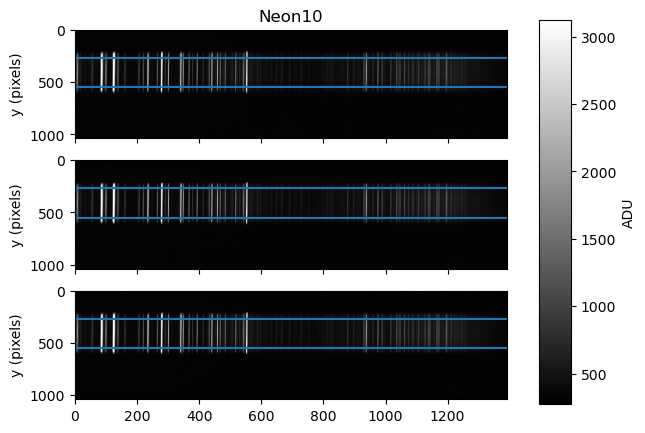

In [3]:
frames = []

fig, axs = plt.subplots(3, 1, sharex=True)

for i in range(len(hduls) // 2):
    frames.append(hduls[i][0].data.astype(float))
    hduls[i].close()
    
    vmin, vmax = np.percentile(frames[i], [1, 99.5])
    im = axs[i].imshow(frames[i], origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')
    
    if i == len(hduls) - 1:
        axs[i].set_xlabel('x (pixels)')
    
    axs[i].set_ylabel('y (pixels)')
    
    if i == 0:
        axs[i].set_title(hdrs[i]["OBJECT"])
    
    # y-pixel range of interest
    axs[i].axhline(270)
    axs[i].axhline(550)
    
fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.1, 0.05, 0.8])
fig.colorbar(im, label='ADU', cax=cbar_ax)
plt.show()

Let's check if the lines are straight. If they are not, we have to take that into consideration when merging the frames and collapsing their y-axis.

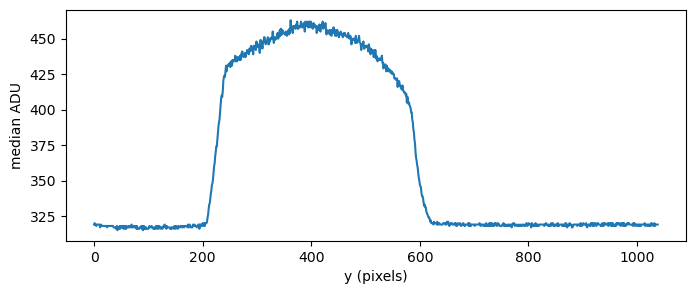

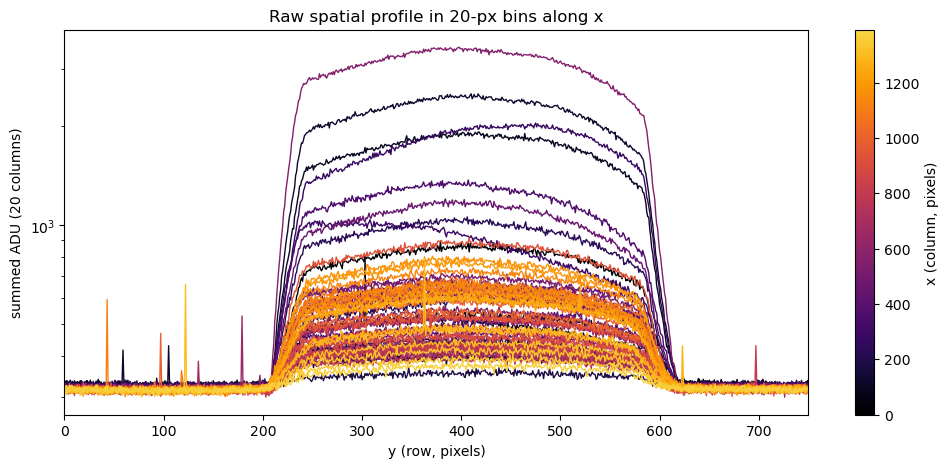

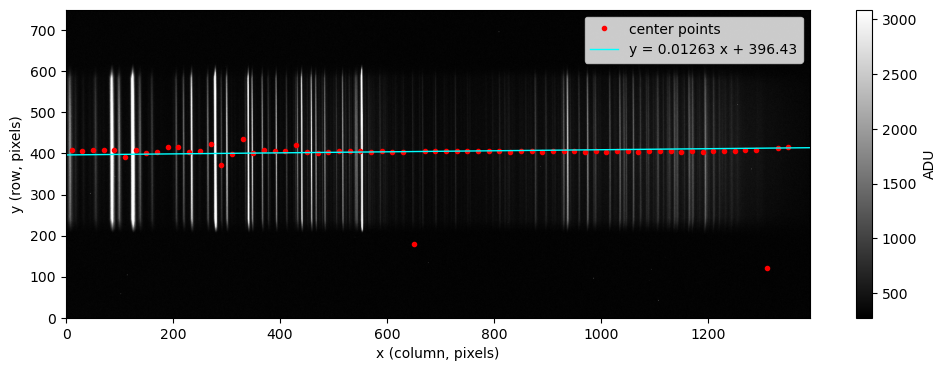

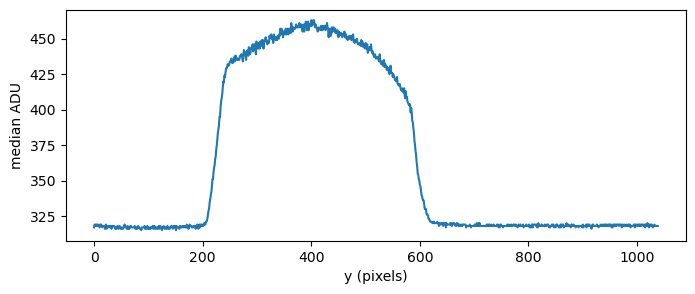

/tmp/ipykernel_182/2367808269.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(gaussian, y, prof, p0=p0)


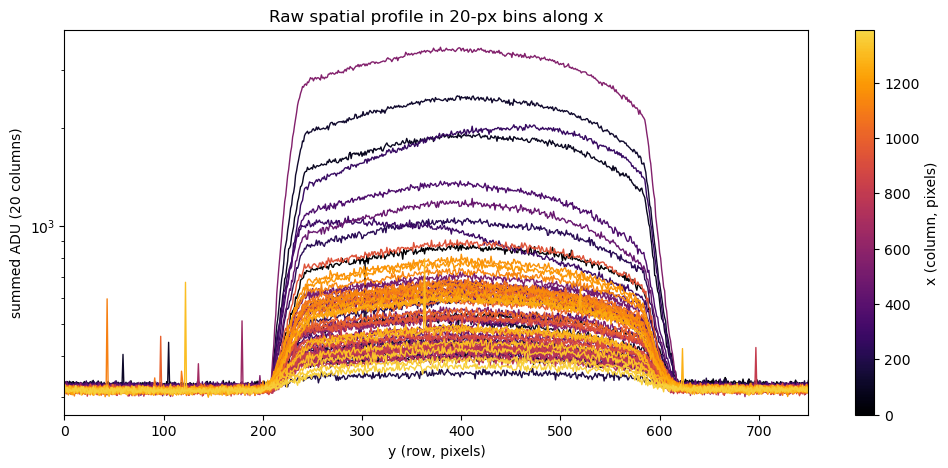

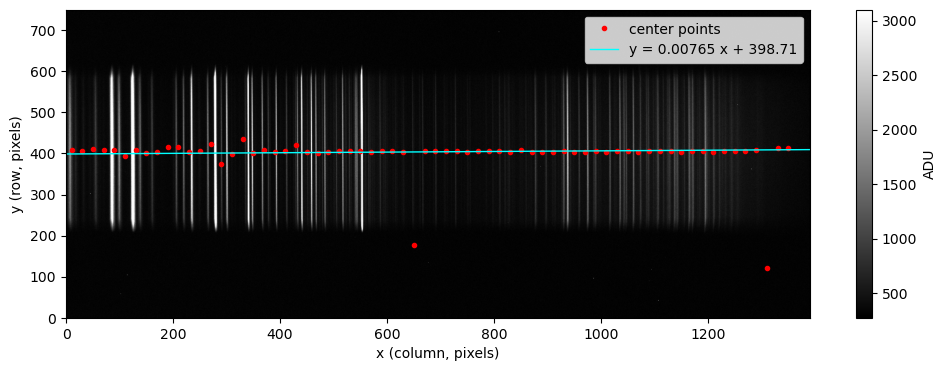

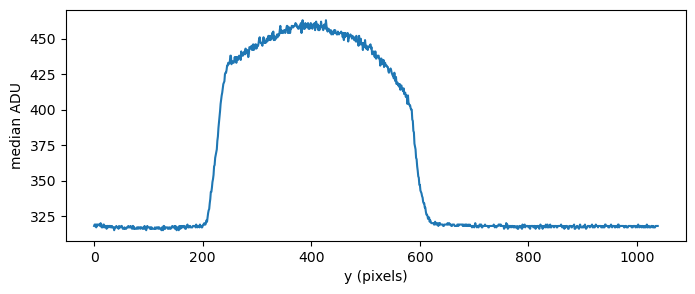

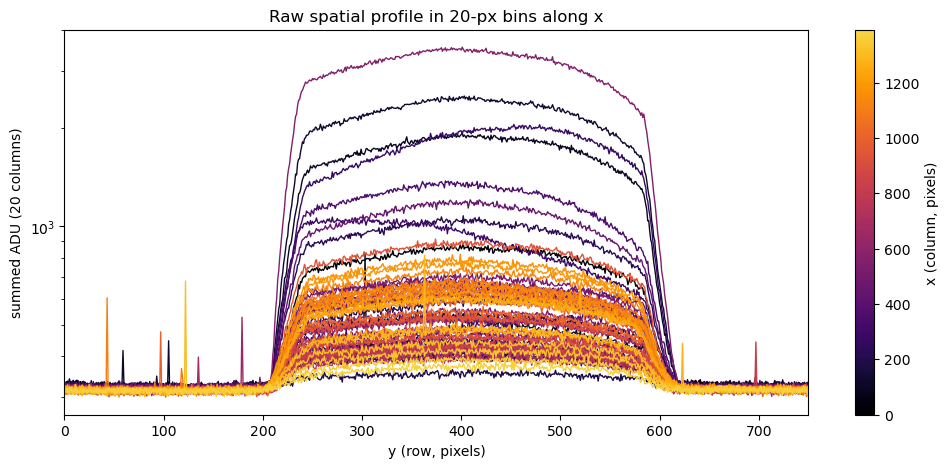

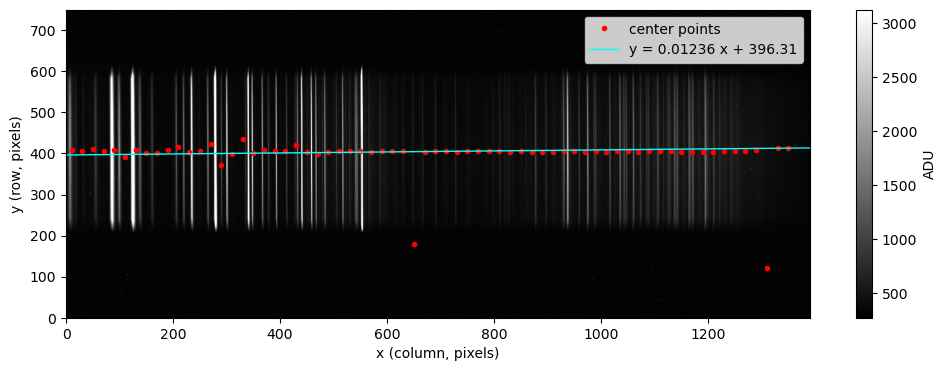

In [4]:
for data in frames:
    # Collapse x-axis to get aperture 
    row_prof = np.median(data, axis=1)
    y = np.arange(data.shape[0])


    # By eye guess what aperture halfwidth is
    aperture_halfwidth = 200 # pixels


    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(y, row_prof, label='data')

    ax.set_xlabel('y (pixels)')
    ax.set_ylabel('median ADU')
    plt.show()

    # Chunk original data rows into bins of 20 pixels, see if there's a drift 
    from matplotlib.colors import ListedColormap

    bin_width = 20 # how many pixels to average
    nrows, ncols = data.shape
    nbins = ncols // bin_width  

    # 1) chunk: (rows, nbins, bin_width)
    chunks = data[:, :nbins * bin_width].reshape(nrows, nbins, bin_width)

    # 2) sum the pixels in each bin -> (rows, nbins)
    binned_sum = chunks.sum(axis=2)/bin_width   # average ADU per column in each bin

    # 3) Calculate bin centers 
    x_centres = (np.arange(nbins) + 0.5) * bin_width


    cmap = ListedColormap(plt.cm.inferno(np.linspace(0, 0.9, 256)))   # drop the near-white end
    norm = plt.Normalize(0, ncols)
    fig, ax = plt.subplots(figsize=(12, 5))
    for i in range(nbins):
        ax.semilogy(y, binned_sum[:, i], color=cmap(norm(x_centres[i])), lw=1)

    ax.set(xlabel='y (row, pixels)', ylabel=f'summed ADU ({bin_width} columns)',
           title=f'Raw spatial profile in {bin_width}-px bins along x')
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, label='x (column, pixels)');

    ax.set_xlim(0,750)
    
    from scipy.optimize import curve_fit

    # Define function to fit to each of these peaks 
    def gaussian(y, amp, mu, sigma, offset):
        return amp * np.exp(-0.5 * ((y - mu) / sigma)**2) + offset


    # Fit a Gaussian to each binned profile
    y_centres = np.full(nbins, np.nan)
    y_errs = np.full(nbins, np.nan)
    for i in range(nbins):
        prof = binned_sum[:, i]
        p0 = [prof.max() - np.median(prof), np.argmax(prof), 5, np.median(prof)] # Initial guess to give optimizer
        try:
            popt, pcov = curve_fit(gaussian, y, prof, p0=p0)
            y_centres[i], y_errs[i] = popt[1], np.sqrt(pcov[1, 1])
        except RuntimeError:                         
            pass

    # Fit a line to the centers 
    # good = np.isfinite(y_centres)
    slope, intercept = np.polyfit(x_centres, y_centres, 1)
    x_line = np.arange(ncols)


    # Overplot the fitted centres on the image
    fig, ax = plt.subplots(figsize=(12, 4))
    vmin, vmax = np.percentile(data, [1, 99.5])
    im = ax.imshow(data, origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')
    ax.plot(x_centres, y_centres, marker='o',ls='none', ms=3, color='red', label='center points')
    ax.plot(x_line, slope * x_line + intercept, color='cyan', lw=1,
            label=f'y = {slope:.5f} x + {intercept:.2f}')
    ax.set(xlabel='x (column, pixels)', ylabel='y (row, pixels)')
    ax.legend(loc='upper right')
    fig.colorbar(im, label='ADU')

    ax.set_ylim(0,750)

    plt.show()

Some points are very obviously outliers, so we can repeat our fit without them. We will only take into consideration bins that fall within the 390-410 y-pixel range.

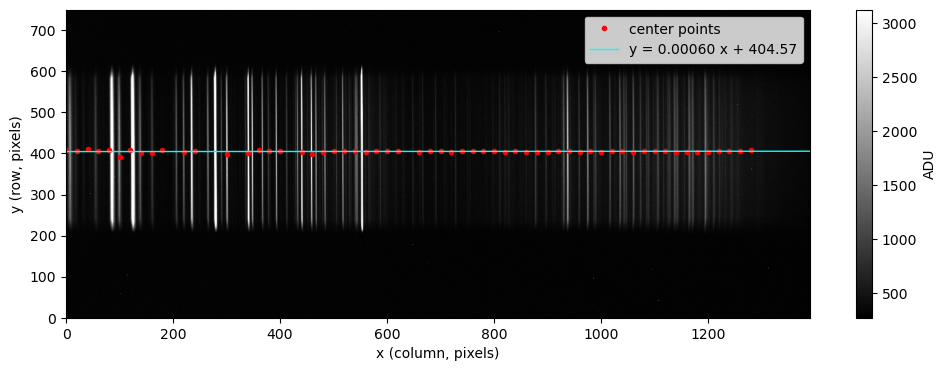

In [5]:
# Fit a Gaussian to each binned profile
filtered_y_centres = []
filtered_x_centres = []
curr_bin = 0
bin_ct = 0

for centre in y_centres:
    if 390 <= centre <= 410:
        filtered_y_centres.append(centre)
        filtered_x_centres.append(curr_bin)
        bin_ct += 1
    curr_bin += bin_width

filtered_y_errs = np.full(bin_ct, np.nan)

i = 0

for bin_num in filtered_x_centres:
    prof = binned_sum[:, bin_num//bin_width]
    p0 = [prof.max() - np.median(prof), np.argmax(prof), 5, np.median(prof)] # Initial guess to give optimizer
    try:
        popt, pcov = curve_fit(gaussian, y, prof, p0=p0)
        filtered_y_centres[i], filtered_y_errs[i] = popt[1], np.sqrt(pcov[1, 1])
    except RuntimeError:                         
        pass
    i += 1

# Fit a line to the centers 
# good = np.isfinite(y_centres)
slope, intercept = np.polyfit(filtered_x_centres, filtered_y_centres, 1)
x_line = np.arange(ncols)


# Overplot the fitted centres on the image
fig, ax = plt.subplots(figsize=(12, 4))
vmin, vmax = np.percentile(data, [1, 99.5])
im = ax.imshow(data, origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')
ax.plot(filtered_x_centres, filtered_y_centres, marker='o',ls='none', ms=3, color='red', label='center points')
ax.plot(x_line, slope * x_line + intercept, color='cyan', lw=1,
        label=f'y = {slope:.5f} x + {intercept:.2f}')
ax.set(xlabel='x (column, pixels)', ylabel='y (row, pixels)')
ax.legend(loc='upper right')
fig.colorbar(im, label='ADU')

ax.set_ylim(0,750)

plt.show()

This is looking great! With outlier values removed, the line looks pretty much straight (a difference of 0.6 pixels in the y-axis per 1000 pixels on the x-axis). Let's combine them by averaging. We'll also get a standard deviation for each pixel that way!

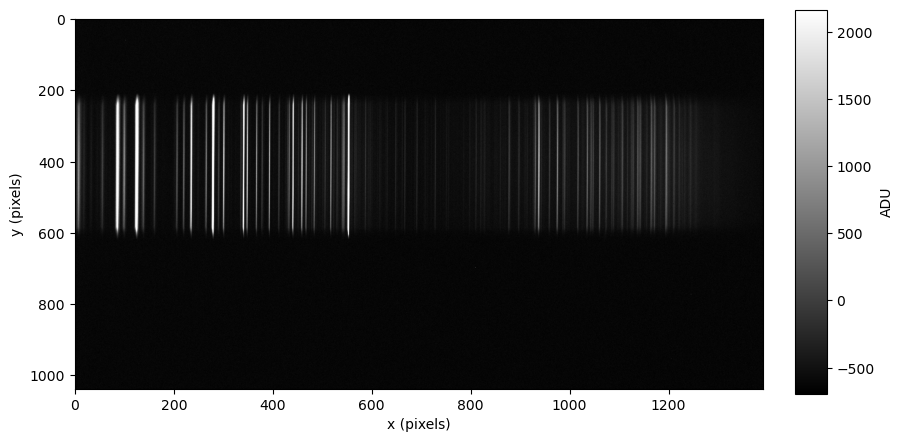

In [6]:
frames = np.array(frames)
avg_frame = np.zeros((1039, 1391))
std_frame = np.std(frames, axis=-1)

for frame in frames:
    avg_frame += frame

avg_frame /= len(frames)

avg_frame.shape

# dark subtraction
darks = []
avg_dark = np.zeros((1039, 1391))

for i in range(3, len(hduls)):
    darks.append(hduls[i][0].data.astype(float))
    hduls[i].close()

darks = np.array(darks)

std_dark = np.std(darks, axis=-1)

for dark in darks:
    avg_dark += dark

avg_sub = avg_frame - avg_dark
std_sub = np.sqrt(std_frame ** 2 + std_dark ** 2)

# plot our average dark-subtracted image!
fig, ax = plt.subplots(1, 1)

vmin, vmax = np.percentile(avg_sub, [1, 99.5])
im = ax.imshow(avg_sub, origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')

ax.set_xlabel('x (pixels)')
ax.set_ylabel('y (pixels)')

fig.subplots_adjust(right=1.2)
cbar_ax = fig.add_axes([1.25, 0.1, 0.05, 0.8])
fig.colorbar(im, label='ADU', cax=cbar_ax)
plt.show()

We can take values in the 390-410 y-pixel range to collapse, as that is what we selected bins to verify how straight the fit was.

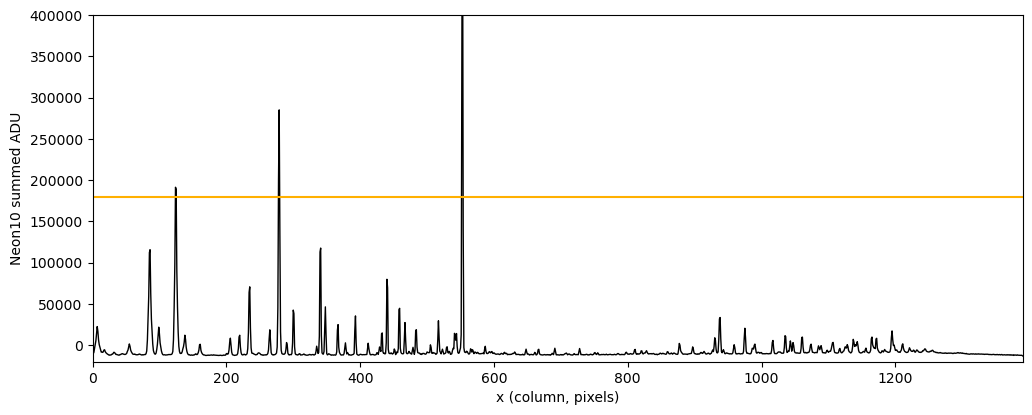

In [7]:
to_collapse = []
for row in avg_sub[390:411]:
        to_collapse.append(row)

# Calculate trace 
x_cols = np.arange(ncols)
trace_y = slope * x_cols + intercept

to_collapse = np.array(to_collapse)

# Extract signal inside of aperture 
in_aperture = np.abs(y[390:411, None] - trace_y[None, :]) <= aperture_halfwidth
ap_lo, ap_hi = trace_y - aperture_halfwidth, trace_y + aperture_halfwidth

# Collapse over y-column axis to get spectrum
spectrum = np.where(in_aperture, to_collapse, 0).sum(axis=0) # zero out data outside of aperture

# Plot spectrum
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(x_cols, spectrum, color='k', lw=1, label=f"{hdrs[0]['OBJECT']} ")
ax.set(xlabel='x (column, pixels)', ylabel=f"{hdrs[0]['OBJECT']} summed ADU", xlim=(0, ncols - 1))
ax.set_ylim(-20000, 400000)
peak_threshold = 180000

ax.axhline(peak_threshold, color='#FFB000', label='peak threshold')

Looking good, let's find some peaks! We will only consider peaks above 400000 for now (yellow line above), and add more if needed.

In [8]:
peaks = scp.signal.find_peaks(spectrum, peak_threshold)
print(f"Number of peaks above {peak_threshold} ADUs: {len(peaks[0])}\n" + 
      f"Locations:\n{[peak for peak in peaks[0]]}")

Number of peaks above 180000 ADUs: 3
Locations:
[np.int64(124), np.int64(279), np.int64(553)]


The 3 peaks above 20000 ADUs are known wavelengths of the Ne/Ar spectrum: 703.2nm, 667.8nm, and 585.2nm. We will start with these to get a preliminary fit, and identify more points to work back and get a better fit with.

In [9]:
def centroid(peak, around, values):
    """
    Return a weighed average of the location of the peak based on values, 
    use values around the peak index to calculate this average.
    """
    val = 0
    value_sum = 0
    for i in range((peak - around) , (peak + around + 1)):
        val += values[i] * i
        value_sum += values[i]
    
    return val/value_sum

centroids = []
around = 5 # use 5 values on either side of each peak for centroid calculation

for peak in peaks[0]:
    centroids.append(centroid(peak, around, spectrum))
    
centroids = np.array(centroids)

ne_ar_wavelengths = [7032, 6678, 5852]

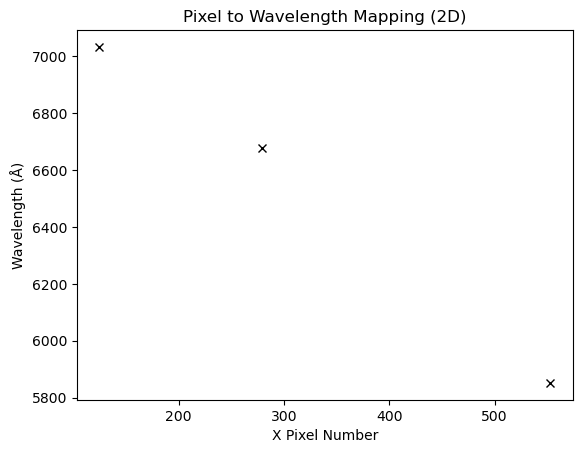

In [10]:
plt.plot(centroids, ne_ar_wavelengths, 'x', color = 'k')
plt.title("Pixel to Wavelength Mapping (2D)")
plt.xlabel("X Pixel Number")
plt.ylabel("Wavelength (Å)")
plt.show()

Let's try fitting our plot with different polynomials! 2-order polynomials are guaranteed to have a unique solution, and 3-order and higher an infinite number of solutions (hence the warning about a cubic fit being "poorly conditioned")

/tmp/ipykernel_182/1561072904.py:6: RankWarning: Polyfit may be poorly conditioned
  p3 = np.polyfit(centroids, ne_ar_wavelengths, 3)   # cubic


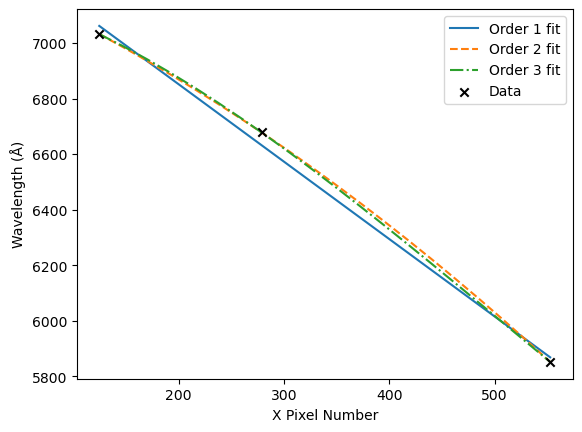

In [11]:
# -----------------------
# Fit polynomials -> param
# -----------------------
p1 = np.polyfit(centroids, ne_ar_wavelengths, 1)   # linear
p2 = np.polyfit(centroids, ne_ar_wavelengths, 2)   # quadratic
p3 = np.polyfit(centroids, ne_ar_wavelengths, 3)   # cubic

# Turn coefficients into functions
f1 = np.poly1d(p1)
f2 = np.poly1d(p2)
f3 = np.poly1d(p3)

# Smooth x-axis for plotting
xfit = np.linspace(np.min(centroids), np.max(centroids), 20)

# -----------------------
# Plot
# -----------------------

plt.plot(xfit, f1(xfit), label="Order 1 fit", linestyle='-')
plt.plot(xfit, f2(xfit), label="Order 2 fit", linestyle='--')
plt.plot(xfit, f3(xfit), label="Order 3 fit", linestyle='-.')

plt.scatter(centroids, ne_ar_wavelengths, label="Data", color = 'k', marker = 'x', zorder=10)

plt.xlabel("X Pixel Number")
plt.ylabel("Wavelength (Å)")
plt.legend()
plt.show()

We can check the residuals; both the quadratic and cubic should have zero residuals.

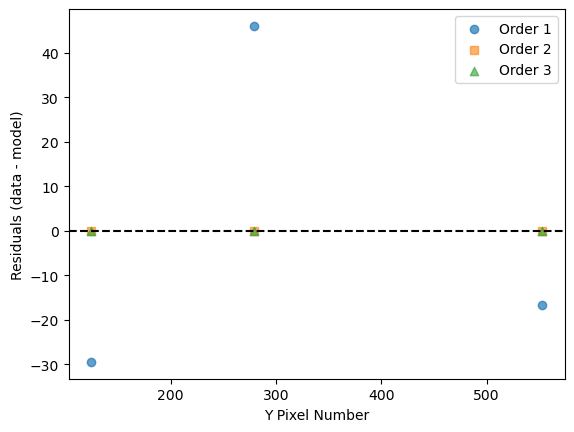

In [12]:
# Model predictions at the SAME x values as the data
y1_model = f1(centroids)
y2_model = f2(centroids)
y3_model = f3(centroids)

# Residuals
resid1 = ne_ar_wavelengths - y1_model
resid2 = ne_ar_wavelengths - y2_model
resid3 = ne_ar_wavelengths - y3_model


plt.axhline(0, color = 'k', linestyle="--")  # zero line
plt.scatter(centroids, resid1, marker='o', label='Order 1', alpha = 0.7)
plt.scatter(centroids, resid2, marker='s', label='Order 2', alpha = 0.6)
plt.scatter(centroids, resid3, marker='^', label='Order 3', alpha = 0.6)

plt.xlabel("Y Pixel Number")
plt.ylabel("Residuals (data - model)")
plt.legend()
plt.show()

We can now replot using our cubic function!

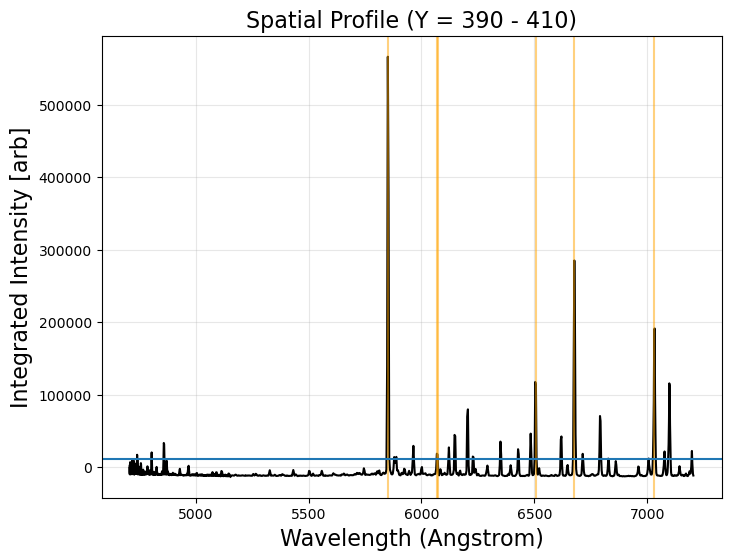

In [13]:
y_min, y_max = 390, 410 # range of rows used in calibration

new_lines = [6074,6069,6506]

plt.figure(figsize=(8,6))
plt.plot(f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in ne_ar_wavelengths + new_lines]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)

lower_threshold = 12000

plt.axhline(lower_threshold)
plt.show()

In [14]:
more_peaks = scp.signal.find_peaks(spectrum, lower_threshold)
angstrom_peaks = f3(more_peaks[0])

print(more_peaks[0])
print(angstrom_peaks)

print(len(more_peaks[0]))

[   7   86   99  124  138  220  235  265  279  300  341  348  367  393
  433  440  459  467  484  517  541  544  553  938  975 1195]
[7198.34004216 7098.26962621 7077.16461268 7033.21412627 7006.75019719
 6827.7921343  6791.09305304 6714.51145829 6677.42539173 6620.32539404
 6504.31335439 6483.97422822 6428.08083607 6350.14267988 6227.6063059
 6205.90361923 6146.70153712 6121.66658504 6068.30910409 5964.39402714
 5888.82988694 5879.39897608 5851.13690886 4858.5370697  4804.78614211
 4740.44436558]
26


We select the peaks that have no near bright peaks (using the relative intensity scale in the NIST database; if we see there's many peaks within a few Angstrom, we ignore these. This applies to the peak at  5964.6 A for instance).

In [15]:
##########
# Other peaks
##########
smaller_peaks = [4799.82460991, 4854.3887522, 6121.98985786, 6206.24316711, 6350.47228422, 
                 6504.58345679, 6714.62433996, 6791.12722169, 7097.85865722, 7197.71485825]
smaller_pixel = np.array([more_peaks[0][24], more_peaks[0][23], more_peaks[0][17], more_peaks[0][15],
                          more_peaks[0][13], more_peaks[0][10], more_peaks[0][7], more_peaks[0][6],
                          more_peaks[0][1], more_peaks[0][0]])

actual_smaller = [4788, 4852, 6128, 6205, 6351, 
                  6506, 6717, 6759, 7067, 7174]

##########
# 5 KA peaks
##########

five_k_peaks = scp.signal.find_peaks(spectrum, (-5500, 1000))

print(five_k_peaks[0])
print(f3(five_k_peaks[0]))

five_k = [5112.08731268, 5327.09163822, 5431.66173407, 5501.76372279, 5744.99158303]
five_k_pixel = np.array([five_k_peaks[0][15], five_k_peaks[0][14], five_k_peaks[0][13],
                five_k_peaks[0][12], five_k_peaks[0][10]])

print(five_k_pixel)
five_k_actual = [5037, 5331, 5434, 5494, 5748]

[ 335  429  451  479  505  523  530  539  565  568  587  648  667  691
  728  811  897  943  959  986 1085 1089 1117 1125 1128 1140 1156 1169
 1184 1198 1221 1244]
[6521.63120343 6239.97778556 6171.67668393 6084.02136241 6002.20551032
 5945.49004392 5923.44342595 5895.1195973  5813.54311143 5804.16365585
 5744.97777106 5558.66294425 5502.21694172 5432.30276125 5328.06933397
 5114.04624698 4929.79398118 4850.66712916 4826.74108063 4790.87227507
 4712.86882263 4711.63886298 4707.54617786 4707.86189751 4708.15415934
 4710.28348692 4715.55259145 4721.92311398 4731.65458876 4743.0878843
 4766.92548101 4797.2295314 ]
[811 728 691 667 587]


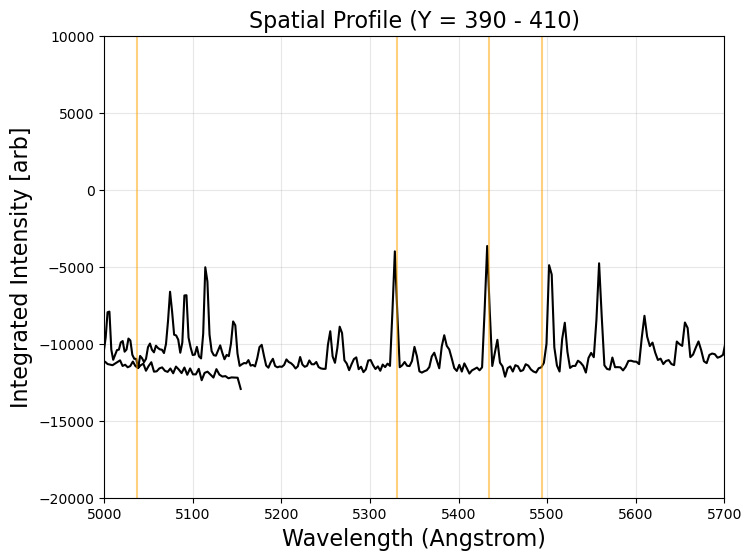

[5037, 5331, 5434, 5494, 5748]


In [16]:
y_min, y_max = 390, 410 # range of rows used in calibration

new_lines = [6074,6069,6506]

plt.figure(figsize=(8,6))
plt.plot(f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in ne_ar_wavelengths + five_k_actual]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)

plt.xlim(5000, 5700)
plt.ylim(-20000, 10000)

plt.axvline(811)
plt.show()

print(five_k_actual)

With these, it would be best to also get peaks in the 5000-5700 A range, so we will look for these specifically.

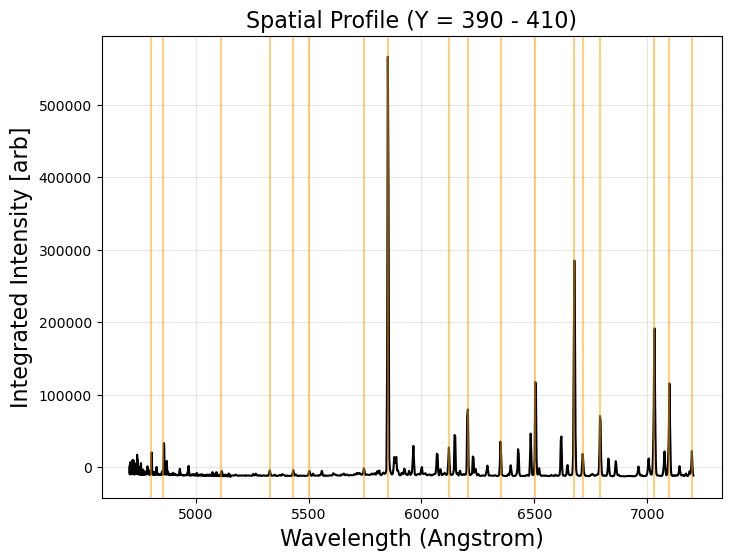

In [17]:
plt.figure(figsize=(8,6))
plt.plot(f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in ne_ar_wavelengths + smaller_peaks + five_k]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.show()

With the location of these peaks in pixel now identified, we can perform the same centroid calculations as previously to plot the calibration graph.

In [18]:
# concatenate main peaks, smaller peaks, and 5 KA peaks
all_points = np.concatenate((peaks[0], smaller_pixel, five_k_pixel))
all_expected_peaks = np.concatenate((np.array(ne_ar_wavelengths), 
                                     np.array(actual_smaller),
                                    np.array(five_k_actual)))

around = 2

all_centroids = np.array([centroid(p, around, spectrum) for p in all_points])

Let's plot expected wavelengths against centroids to check for any visible relationship!

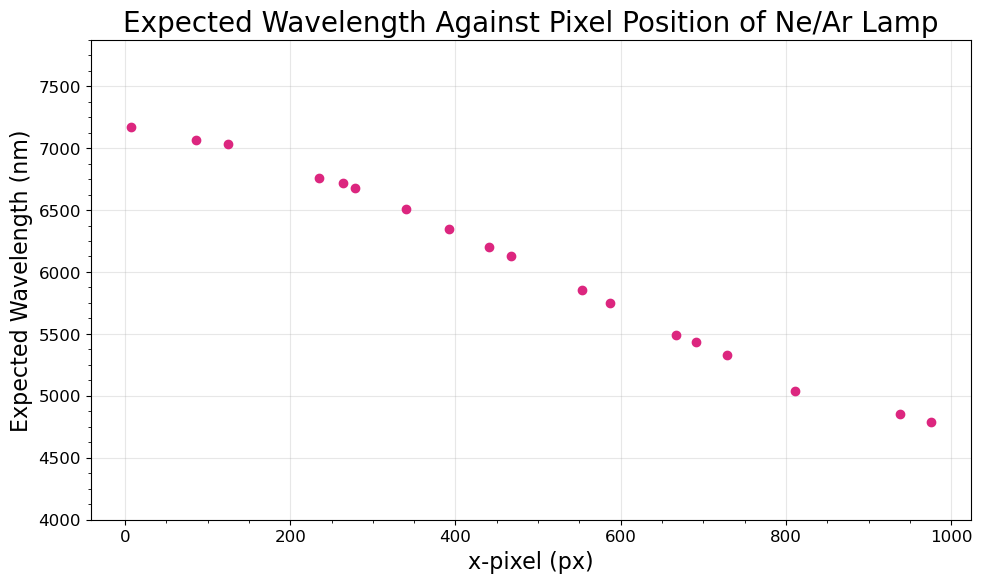

In [19]:
lin_range = np.arange(int(np.min(all_centroids)), int(np.max(all_centroids) + 1), 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########

ax.scatter(all_centroids, all_expected_peaks, color="#DC267F", label="scatter", zorder=10)

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 125), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)

ax.grid(visible=True, alpha=0.3)

This looks somewhat like a cubic, or higher order odd polynomial! Let's check this by trying a cubic, 5th order, and 7th order polynomial.

In [20]:
p1, c1 = np.polyfit(all_centroids, all_expected_peaks, 1, cov=True)
f1 = np.poly1d(p1)

# try a square just in case
p2, c2, = np.polyfit(all_centroids, all_expected_peaks, 2, cov=True)
f2 = np.poly1d(p2)

p3, c3 = np.polyfit(all_centroids, all_expected_peaks, 3, cov=True)
f3 = np.poly1d(p3)

p5, c5 = np.polyfit(all_centroids, all_expected_peaks, 5, cov=True)
f5 = np.poly1d(p5)

p7, c7 = np.polyfit(all_centroids, all_expected_peaks, 7, cov=True)
f7 = np.poly1d(p7)

p9, c9 = np.polyfit(all_centroids, all_expected_peaks, 9, cov=True)
f9 = np.poly1d(p9)

p11, c11 = np.polyfit(all_centroids, all_expected_peaks, 11, cov=True)
f11 = np.poly1d(p11)

p13, c13 = np.polyfit(all_centroids, all_expected_peaks, 13, cov=True)
f13 = np.poly1d(p13)

p15, c15 = np.polyfit(all_centroids, all_expected_peaks, 15, cov=True)
f15 = np.poly1d(p15)

Sum of absolute residuals:
1st:	1052.8242705690373
3rd:	202.47448804726992
5th:	207.20706731198425
7th:	195.89224616191223
9th:	112.91143544824172
11th:	57.87124772659445
13th:	30.181477864791304
15th:	23.55343552863269



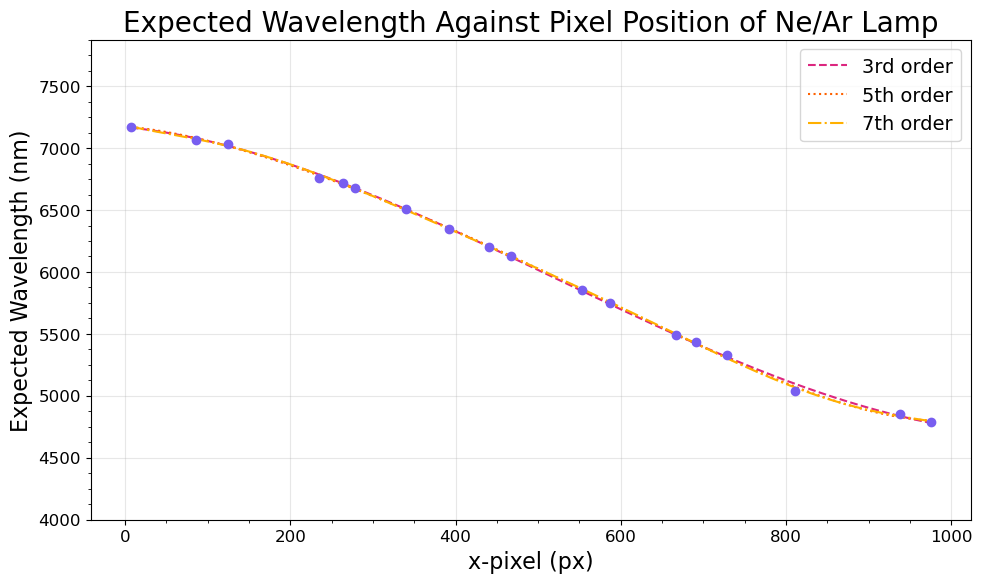

In [21]:
def residuals(data, expected, fn):
    """
    Return residuals per point in data of fn(data) compared to expected as a NumPy array. 
    len(data) == len(expected)
    """
    residual = []
    for i in range(len(data)):
        residual.append(expected[i] - fn(data[i]))
        
    return np.array(residual)

f1_res = residuals(all_centroids, all_expected_peaks, f1)
f2_res = residuals(all_centroids, all_expected_peaks, f2)
f3_res = residuals(all_centroids, all_expected_peaks, f3)
f5_res = residuals(all_centroids, all_expected_peaks, f5)
f7_res = residuals(all_centroids, all_expected_peaks, f7)
f9_res = residuals(all_centroids, all_expected_peaks, f9)
f11_res = residuals(all_centroids, all_expected_peaks, f11)
f13_res = residuals(all_centroids, all_expected_peaks, f13)
f15_res = residuals(all_centroids, all_expected_peaks, f15)

lin_range = np.arange(int(np.min(all_centroids)), int(np.max(all_centroids) + 1), 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########

ax.scatter(all_centroids, all_expected_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, f3(lin_range), color="#DC267F", ls="--", label="3rd order")
ax.plot(lin_range, f5(lin_range), color="#FE6100", ls=":", label="5th order")
ax.plot(lin_range, f7(lin_range), color="#FFB000", ls="-.", label="7th order")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 125), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

print(f"Sum of absolute residuals:\n" + 
      f"1st:\t{np.sum(np.abs(f1_res))}\n"
      f"3rd:\t{np.sum(np.abs(f3_res))}\n" +
      f"5th:\t{np.sum(np.abs(f5_res))}\n" + 
      f"7th:\t{np.sum(np.abs(f7_res))}\n" + 
      f"9th:\t{np.sum(np.abs(f9_res))}\n" + 
      f"11th:\t{np.sum(np.abs(f11_res))}\n" + 
      f"13th:\t{np.sum(np.abs(f13_res))}\n" + 
      f"15th:\t{np.sum(np.abs(f15_res))}\n")

It is very interesting to see that a 5th oder polynomial does better than a 7th order one! This most likely is because np.polyfit struggled less with finding appropriate parameters for the 5th order than the 7th (say, if it tries to first find polynomials with a non-zero 7th power, then the fit might overall be weaker than with the 5th order which completely ignores it).<br>

However, all fits except for the cubic function seem to return covariance matrices whose square root of diagonals (std of the parameters) is the same order of magnitude as the values themselves, if not 1 order of magnitude above. Luckily, the cubic seems to consistently have standard deviations one order of magnitude below the values themselves, so we will continue with that fit.

In [22]:
"""
print("Covariance Matrices:\n" + 
     f"1st:\n{c1}\n"
      f"3rd:\n{c3}\n" +
      f"5th:\n{c5}\n" + 
      f"7th:\n{c7}\n" + 
      f"9th:\n{c9}\n" + 
      f"11th:\n{c11}\n" + 
      f"13th:\n{c13}\n" + 
      f"15th:\n{c15}\n")
      
"""

'\nprint("Covariance Matrices:\n" + \n     f"1st:\n{c1}\n"\n      f"3rd:\n{c3}\n" +\n      f"5th:\n{c5}\n" + \n      f"7th:\n{c7}\n" + \n      f"9th:\n{c9}\n" + \n      f"11th:\n{c11}\n" + \n      f"13th:\n{c13}\n" + \n      f"15th:\n{c15}\n")\n\n'

In [23]:
third_errors = np.sqrt(np.diag(c3), dtype=np.float128)

print(p3)
print(third_errors)

[ 3.04993682e-06 -4.79494946e-03 -6.74205035e-01  7.17047697e+03]
[2.27641875e-07 3.43774806e-04 1.45845408e-01 1.71641842e+01]


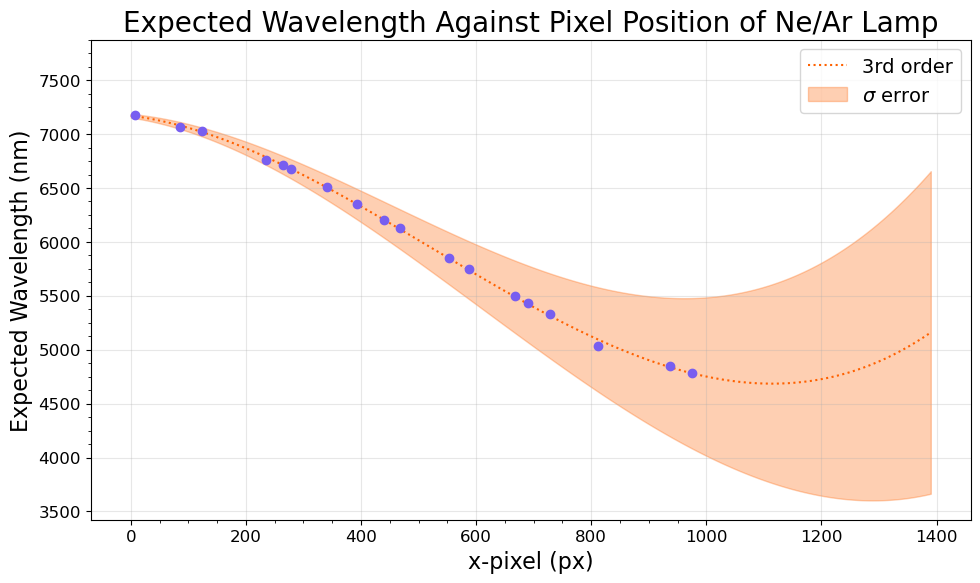

In [24]:
lin_range = np.arange(0, ncols, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
f3_lo = np.poly1d(np.array([p3[0] - third_errors[0], p3[1] - third_errors[1],
                            p3[2] - third_errors[2], p3[3] - third_errors[3]]))

f3_hi = np.poly1d(np.array([p3[0] + third_errors[0], p3[1] + third_errors[1],
                            p3[2] + third_errors[2], p3[3] + third_errors[3]]))

ax.scatter(all_centroids, all_expected_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, f3(lin_range), color="#FE6100", ls=":", label="3rd order")
ax.fill_between(lin_range, f3_lo(lin_range), f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 125), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)


Let's try refitting with our new cubic fit: 

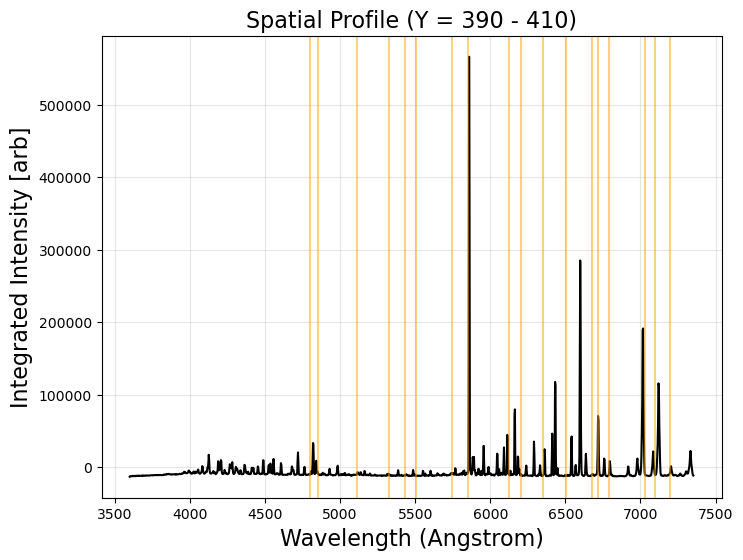

In [25]:
plt.figure(figsize=(8,6))
plt.plot(f1(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in ne_ar_wavelengths + smaller_peaks + five_k]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.show()

That doesn't fit great... what if we try without the first two points, and the 4th one? We'll stay on a cubic since it seems to have the most appropriate shape.

In [26]:
specific_centroids = np.concatenate((all_centroids[:10], all_centroids[13:]))
specific_peaks = np.concatenate((all_expected_peaks[:10], all_expected_peaks[13:]))

print(all_centroids)
# need to remove indices 11, 12 (1st and 2nd points), and 10 (4th point)

new_p3, new_c3 = np.polyfit(specific_centroids, specific_peaks, 3, cov=True)
new_f3 = np.poly1d(new_p3)

[124.29236986 278.82246524 552.75552329 975.11068652 937.27347764
 467.06644151 440.55807772 392.53799332 340.42316642 264.38510792
 234.525407    85.72728304   7.0725218  811.15955244 727.99445921
 691.00370382 667.15561799 587.0314017 ]


In [27]:
new_third_errors = np.sqrt(np.diag(new_c3), dtype=np.float128)

print(new_p3)
print(new_third_errors)

[ 3.17056261e-06 -4.97149257e-03 -6.16481424e-01  7.17271020e+03]
[3.49261938e-07 5.90196064e-04 2.99260454e-01 4.49377234e+01]


That's still some decent standard deviations, let's plot this fit and the corresponding spectrum:

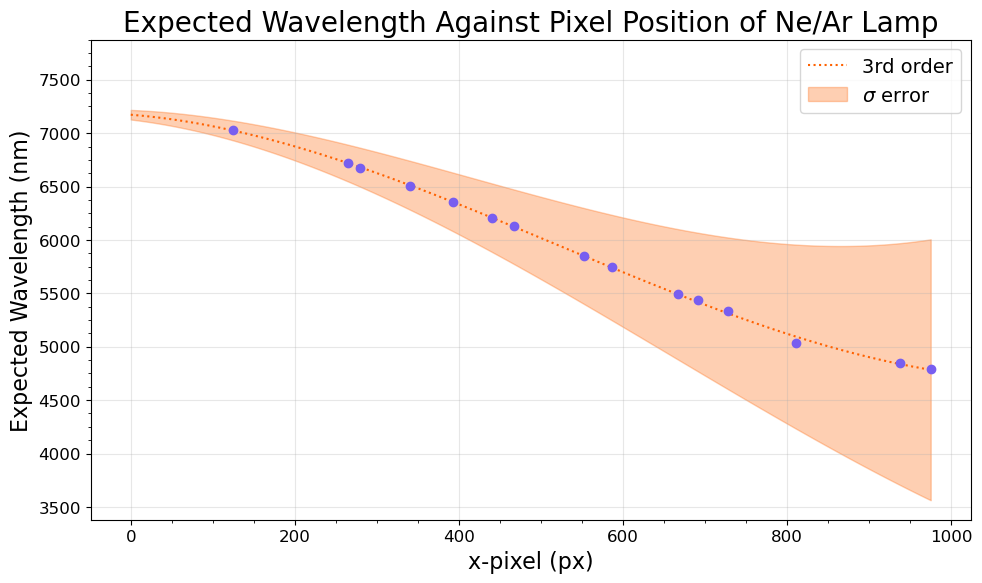

In [28]:
lin_range = np.arange(0, int(np.max(all_centroids) + 1), 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
new_f3_lo = np.poly1d(np.array([new_p3[0] - new_third_errors[0], new_p3[1] - new_third_errors[1],
                            new_p3[2] - new_third_errors[2], new_p3[3] - new_third_errors[3]]))

new_f3_hi = np.poly1d(np.array([new_p3[0] + new_third_errors[0], new_p3[1] + new_third_errors[1],
                            new_p3[2] + new_third_errors[2], new_p3[3] + new_third_errors[3]]))

ax.scatter(specific_centroids, specific_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, new_f3(lin_range), color="#FE6100", ls=":", label="3rd order")
ax.fill_between(lin_range, new_f3_lo(lin_range), new_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 125), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

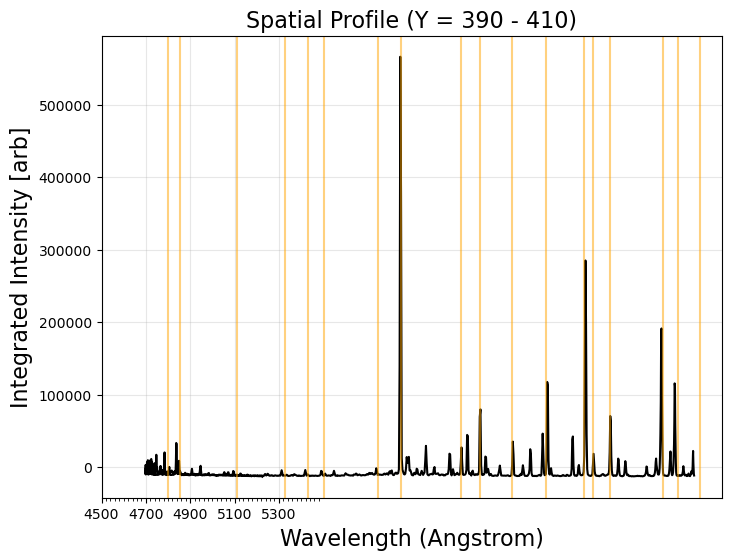

In [29]:
plt.figure(figsize=(8,6))
plt.plot(new_f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in ne_ar_wavelengths + smaller_peaks + five_k]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xticks(np.arange(4500, 5500, 20), minor=True)
plt.xticks(np.arange(4500, 5500, 200))
plt.show()

Yep, that was our fix. That not only makes the calibration significantly better, it also beats our previous standard error by a huge amount. We'll stick with this formula!

In [30]:
print(f"Calibration Equation (Cubic 15-point):\n" + 
      f"(Wavelength =\n {np.round(new_p3[0], 7)} +/- {np.round(new_third_errors[0], 7)})x^3\n" +
      f"{np.round(new_p3[1], 7)} +/- {np.round(new_third_errors[1], 7)})x^2\n" + 
      f"{np.round(new_p3[2], 7)} +/- {np.round(new_third_errors[2], 7)})x\n" + 
      f"+{np.round(new_p3[3], 7)} +/- {np.round(new_third_errors[3], 7)})")

Calibration Equation (Cubic 15-point):
(Wavelength =
 3.2e-06 +/- 3e-07)x^3
-0.0049715 +/- 0.0005902)x^2
-0.6164814 +/- 0.2992605)x
+7172.7101965 +/- 44.9377234)


This still has a few issues however - the spectrum warps on itself in the 4500-5000 A range, meaning that our fit probably does not get the whole picture... it would be best to look for other peaks in that lower range of values (likely in the 4000-4500 A range)

In [31]:
print(ne_ar_wavelengths + actual_smaller + five_k_actual)

[7032, 6678, 5852, 4788, 4852, 6128, 6205, 6351, 6506, 6717, 6759, 7067, 7174, 5037, 5331, 5434, 5494, 5748]


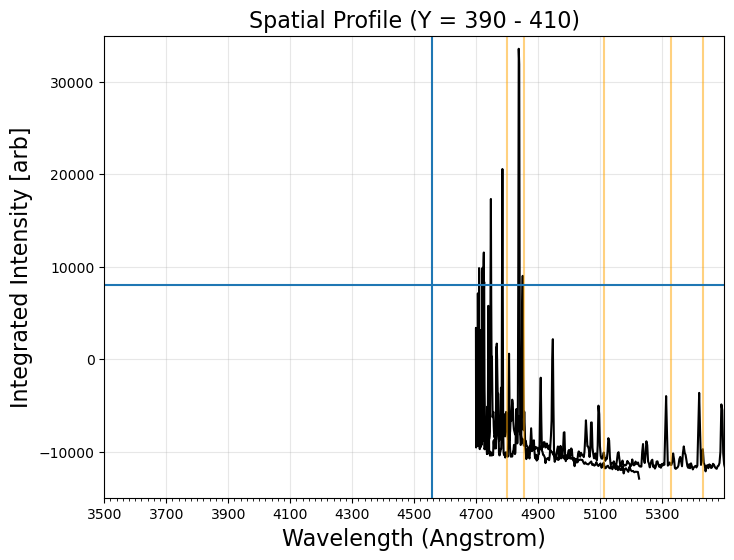

In [32]:
plt.figure(figsize=(8,6))
plt.plot(new_f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in ne_ar_wavelengths + smaller_peaks + five_k]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xticks(np.arange(3500, 5500, 20), minor=True)
plt.xticks(np.arange(3500, 5500, 200))
plt.xlim(3500, 5500)
plt.ylim(-15000, 35000)
plt.axhline(8000)
plt.axvline(f1(1035))
plt.show()

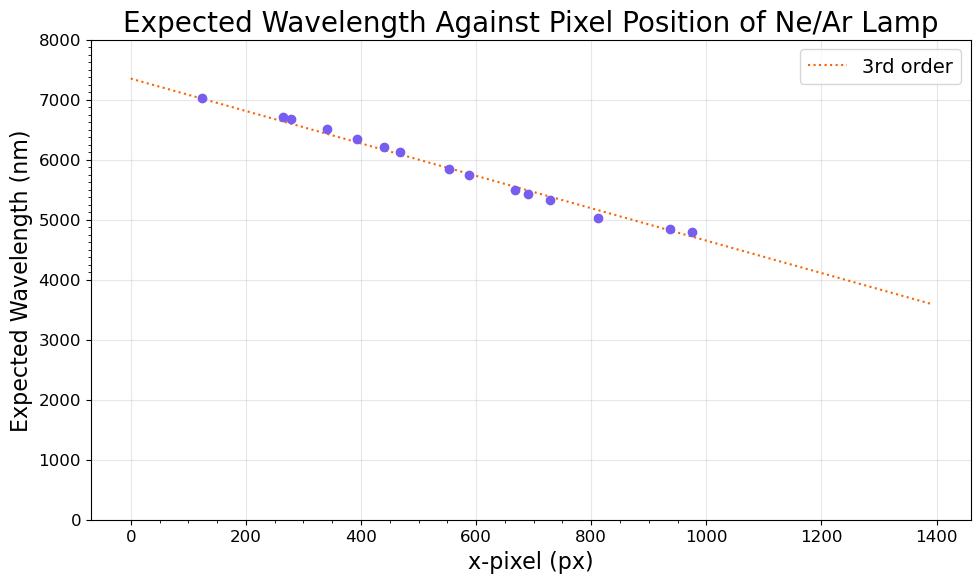

In [33]:
lin_range = np.arange(0, ncols, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
ax.scatter(specific_centroids, specific_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, f1(lin_range), color="#FE6100", ls=":", label="3rd order")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 125), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)
ax.set_ylim(0, 8000)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

In [34]:
scp.signal.find_peaks(spectrum, 8000)

(array([   7,   86,   99,  124,  138,  206,  220,  235,  265,  279,  300,
         341,  348,  367,  393,  433,  440,  459,  467,  484,  517,  541,
         544,  553,  930,  938,  975, 1035, 1061, 1165, 1172, 1195]),
 {'peak_heights': array([ 22598.        , 115772.33333333,  21877.        , 191469.66666667,
          12129.66666667,   8544.        ,  12086.        ,  70763.66666667,
          18643.33333333, 285236.33333333,  42561.66666667, 117749.33333333,
          46483.66666667,  24976.33333333,  35500.        ,  14873.33333333,
          79928.66666667,  44736.33333333,  27471.66666667,  18810.33333333,
          29622.        ,  14411.66666667,  14174.33333333, 566195.66666667,
           9013.        ,  33587.33333333,  20575.66666667,  11538.33333333,
           9851.        ,   9883.33333333,   8354.66666667,  17332.33333333])})

We're interested in peaks at and above index 1035 since that's the range we don't quite cover yet.

The peak at 1035 is likely 4727 A given its amplitude, 1061 should be 4645 A because of its isolation from other peaks in the area. 1195 could be 4401 A since this peak also has two close peaks to the left of it in the NIST database. Let's try adding these to our fit:

In [35]:
new_centroids = [centroid(1195, around, spectrum),
                 all_centroids[12]]

# 4645 A peak (1061) seemed to do more harm than good

new_centroids = np.array(new_centroids)

new_peaks = np.array([4400.9860, all_expected_peaks[12]])

new_centroids = np.concatenate((specific_centroids, new_centroids))
new_peaks = np.concatenate((specific_peaks, new_peaks))

new_peaks[3] = 4715 # has many peaks to left and other peaks to right within few nm - seems like a more logical pick
new_peaks[4] = 4788 # follows from the change of index 3

In [36]:
print(new_centroids)
print(new_peaks)

[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1195.12487363    7.0725218 ]
[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.   ]


In [37]:
nnew_p3, nnew_c3 = np.polyfit(new_centroids, new_peaks, 3, cov=True)
nnew_f3 = np.poly1d(nnew_p3)

nnew_third_errors = np.sqrt(np.diag(nnew_c3), dtype=np.float128)

print(nnew_p3)
print(nnew_third_errors)

[ 2.29314982e-06 -3.87273592e-03 -9.74103245e-01  7.19444045e+03]
[1.12281551e-07 2.04549789e-04 1.05687325e-01 1.59676536e+01]


[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1195.12487363    7.0725218 ]


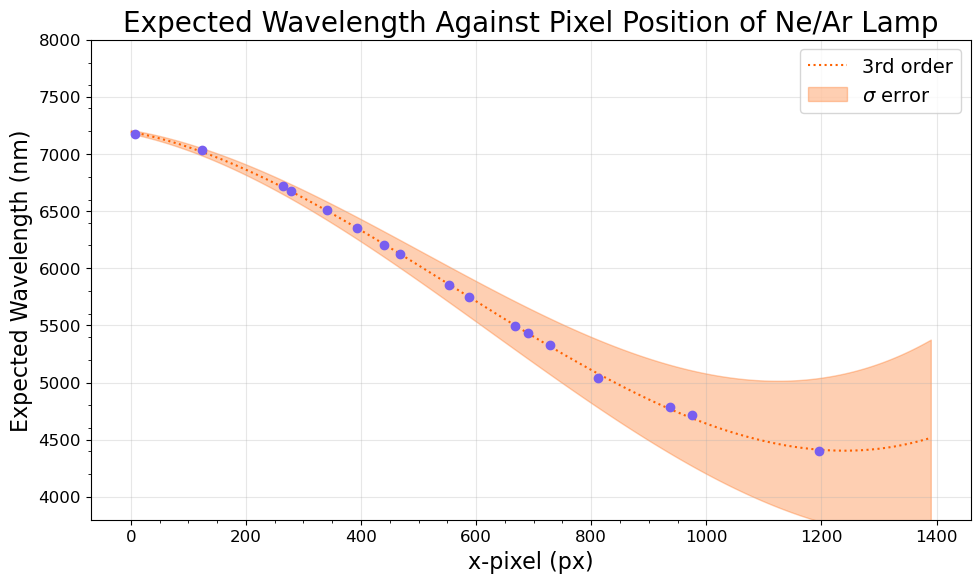

In [38]:
lin_range = np.arange(0, ncols, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
nnew_f3_lo = np.poly1d(np.array([nnew_p3[0] - nnew_third_errors[0], nnew_p3[1] - nnew_third_errors[1],
                            nnew_p3[2] - nnew_third_errors[2], nnew_p3[3] - nnew_third_errors[3]]))

nnew_f3_hi = np.poly1d(np.array([nnew_p3[0] + nnew_third_errors[0], nnew_p3[1] + nnew_third_errors[1],
                            nnew_p3[2] + nnew_third_errors[2], nnew_p3[3] + nnew_third_errors[3]]))

ax.scatter(new_centroids, new_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, nnew_f3(lin_range), color="#FE6100", ls=":", label="3rd order")
ax.fill_between(lin_range, nnew_f3_lo(lin_range), nnew_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 200), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)
ax.set_ylim(3800, 8000)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

print(new_centroids)

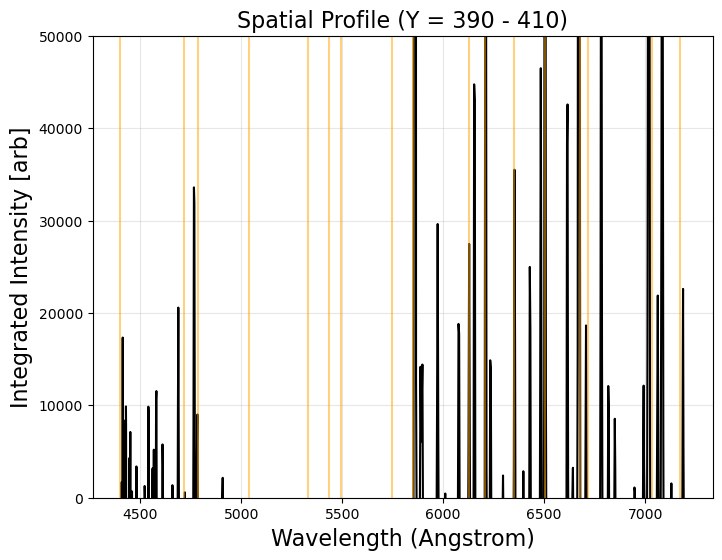

In [39]:
plt.figure(figsize=(8,6))
plt.plot(nnew_f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.ylim(0, 50000)
plt.show()

Let's make a very quick function to return the poly1d calibration function in the data reading notebook.

In [40]:
print(new_peaks)

[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.   ]


This is much better already, but the start of the plot is still wrapping around itself (see the fit plot: the 3rd order line starts increasing around pixel 1250) - we need more points in the 4000-4400 A region still. We'll try finding them using a linear fit over our new data, which should give a rough estimate of what the peaks should be, and we'll go from there.

In [41]:
nnew_p1 = np.polyfit(new_centroids[3:5], new_peaks[3:5], 1, cov=False)
nnew_f1 = np.poly1d(nnew_p1)

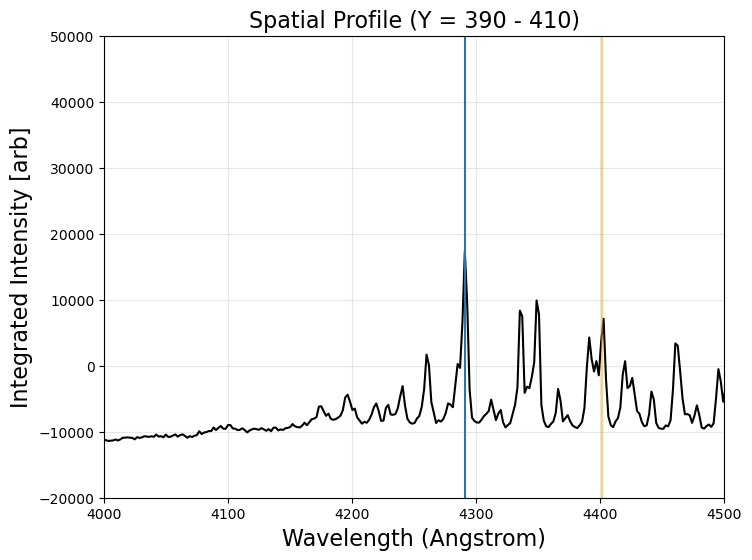

In [42]:
plt.figure(figsize=(8,6))
plt.plot(nnew_f1(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.ylim(-20000, 50000)
plt.xlim(4000,4500)
plt.axvline(nnew_f1(1195))
plt.show()

In [43]:
scp.signal.find_peaks(spectrum, 5000)

(array([   7,   86,   99,  124,  138,  206,  220,  235,  265,  279,  300,
         341,  348,  367,  393,  433,  440,  459,  467,  484,  517,  541,
         544,  553,  930,  938,  975, 1017, 1035, 1043, 1061, 1137, 1165,
        1172, 1195]),
 {'peak_heights': array([ 22598.        , 115772.33333333,  21877.        , 191469.66666667,
          12129.66666667,   8544.        ,  12086.        ,  70763.66666667,
          18643.33333333, 285236.33333333,  42561.66666667, 117749.33333333,
          46483.66666667,  24976.33333333,  35500.        ,  14873.33333333,
          79928.66666667,  44736.33333333,  27471.66666667,  18810.33333333,
          29622.        ,  14411.66666667,  14174.33333333, 566195.66666667,
           9013.        ,  33587.33333333,  20575.66666667,   5766.66666667,
          11538.33333333,   5198.66666667,   9851.        ,   7116.33333333,
           9883.33333333,   8354.66666667,  17332.33333333])})

In [44]:
print(new_peaks)

[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.   ]


In [45]:
# new peak that could actually be our current 4400, which seems to align with another peak instead
new_peaks = np.concatenate((new_peaks, np.array([4131])))
new_centroids = np.concatenate((new_centroids, np.array([centroid(1195, around, spectrum)]))) # swap peak at 1195 with new peak

new_centroids[15] = centroid(1137, around, spectrum) # new peak replacing the original 1195

In [46]:
nnnew_p3, nnnew_c3 = np.polyfit(new_centroids, new_peaks, 3, cov=True)
nnnew_f3 = np.poly1d(nnnew_p3)

[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1068.94875       7.0725218  1195.12487363]


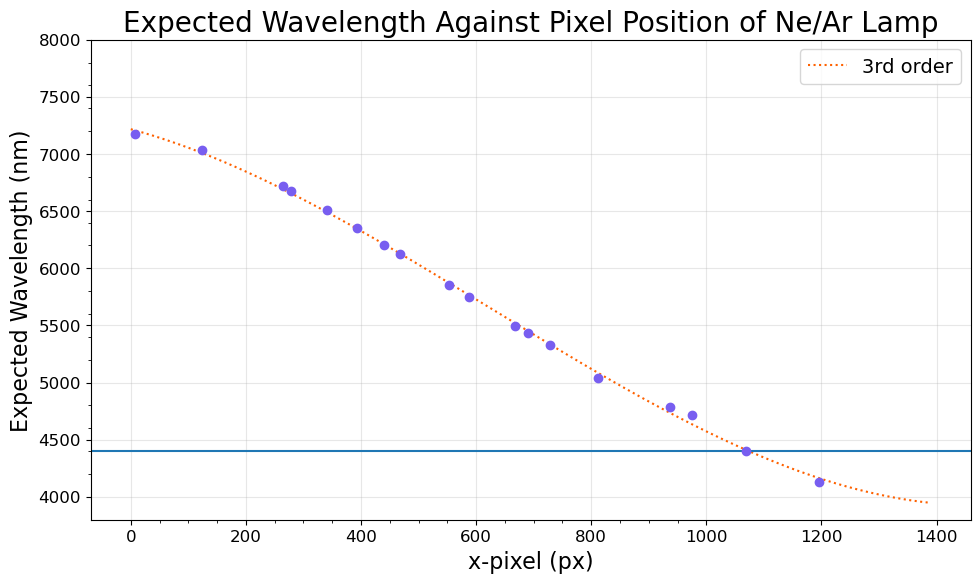

In [47]:
lin_range = np.arange(0, ncols, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
"""
nnew_f3_lo = np.poly1d(np.array([nnew_p3[0] - nnew_third_errors[0], nnew_p3[1] - nnew_third_errors[1],
                            nnew_p3[2] - nnew_third_errors[2], nnew_p3[3] - nnew_third_errors[3]]))

nnew_f3_hi = np.poly1d(np.array([nnew_p3[0] + nnew_third_errors[0], nnew_p3[1] + nnew_third_errors[1],
                            nnew_p3[2] + nnew_third_errors[2], nnew_p3[3] + nnew_third_errors[3]]))
"""
ax.scatter(new_centroids, new_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, nnnew_f3(lin_range), color="#FE6100", ls=":", label="3rd order")

#ax.fill_between(lin_range, nnew_f3_lo(lin_range), nnew_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 200), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)
ax.set_ylim(3800, 8000)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

ax.axhline(4400)

print(new_centroids)

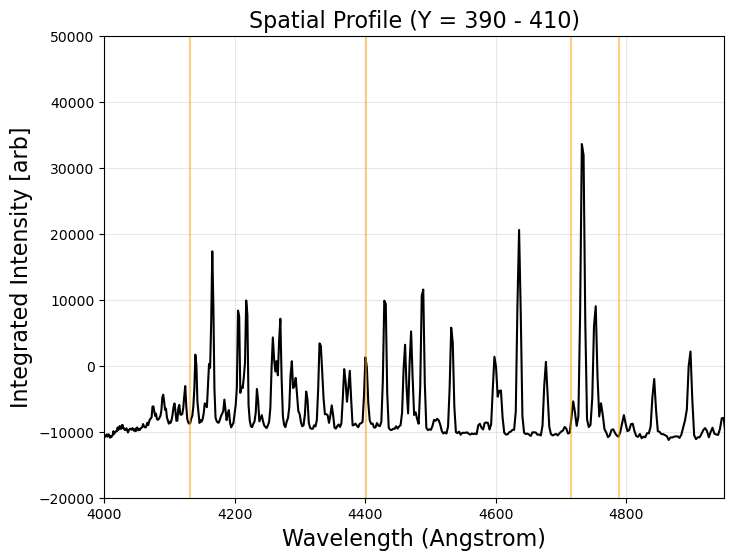

In [48]:
plt.figure(figsize=(8,6))
plt.plot(nnnew_f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.ylim(-20000, 50000)
plt.xlim(4000, 4950)
plt.show()

In [49]:
print(new_peaks)
print(f"{new_centroids}\n\n")

# similar, 1061 and 975 peaks seems to do more harm than good (not isolated)
new_peaks = np.concatenate((new_peaks[:4], new_peaks[5:15], new_peaks[16:]))
new_centroids = np.concatenate((new_centroids[:4], new_centroids[5:15], new_centroids[16:]))

new_peaks[3] = 4590 # seems to be a better fit



print(new_peaks)
print(new_centroids)

[7032.    6678.    5852.    4715.    4788.    6128.    6205.    6351.
 6506.    6717.    5037.    5331.    5434.    5494.    5748.    4400.986
 7174.    4131.   ]
[ 124.29236986  278.82246524  552.75552329  975.11068652  937.27347764
  467.06644151  440.55807772  392.53799332  340.42316642  264.38510792
  811.15955244  727.99445921  691.00370382  667.15561799  587.0314017
 1068.94875       7.0725218  1195.12487363]


[7032. 6678. 5852. 4590. 6128. 6205. 6351. 6506. 6717. 5037. 5331. 5434.
 5494. 5748. 7174. 4131.]
[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  727.99445921  691.00370382  667.15561799  587.0314017     7.0725218
 1195.12487363]


In [50]:
nnnew_p3, nnnew_c3 = np.polyfit(new_centroids, new_peaks, 3, cov=True)
nnnew_f3 = np.poly1d(nnnew_p3)

nnnew_errs = np.sqrt(np.diag(nnnew_c3), dtype=np.float128)

print(nnnew_p3)
print(nnnew_errs)

[ 1.81073881e-06 -3.40647245e-03 -1.07732975e+00  7.19620800e+03]
[8.90634575e-08 1.62556978e-04 8.27938375e-02 1.22201227e+01]


[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  727.99445921  691.00370382  667.15561799  587.0314017     7.0725218
 1195.12487363]


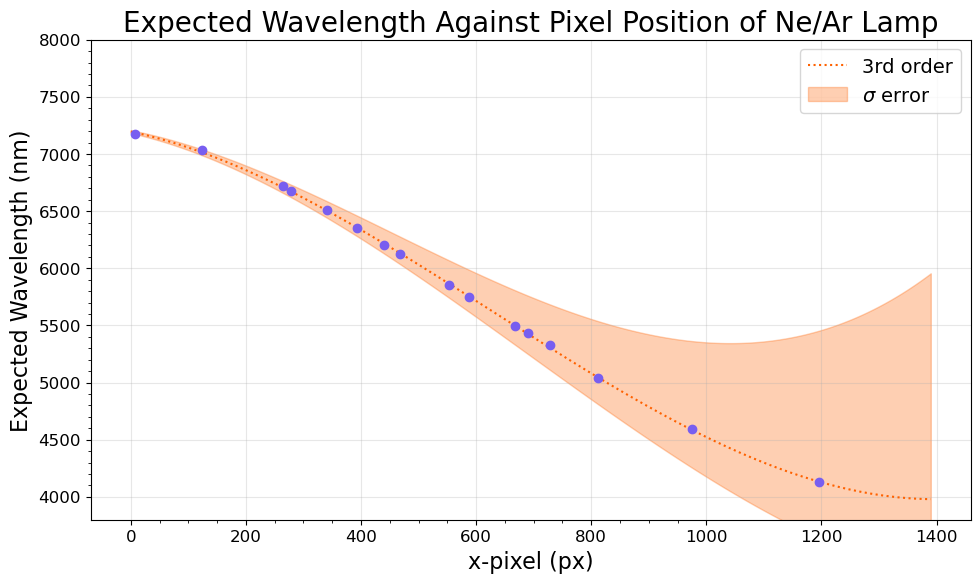

In [51]:
lin_range = np.arange(0, ncols, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
nnnew_f3_lo = np.poly1d(np.array([nnnew_p3[0] - nnnew_errs[0], nnnew_p3[1] - nnnew_errs[1],
                            nnnew_p3[2] - nnnew_errs[2], nnnew_p3[3] - nnnew_errs[3]]))

nnnew_f3_hi = np.poly1d(np.array([nnew_p3[0] + nnnew_errs[0], nnnew_p3[1] + nnnew_errs[1],
                            nnnew_p3[2] + nnnew_errs[2], nnnew_p3[3] + nnnew_errs[3]]))

ax.scatter(new_centroids, new_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, nnnew_f3(lin_range), color="#FE6100", ls=":", label="3rd order")

ax.fill_between(lin_range, nnnew_f3_lo(lin_range), nnnew_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 100), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)
ax.set_ylim(3800, 8000)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

print(new_centroids)

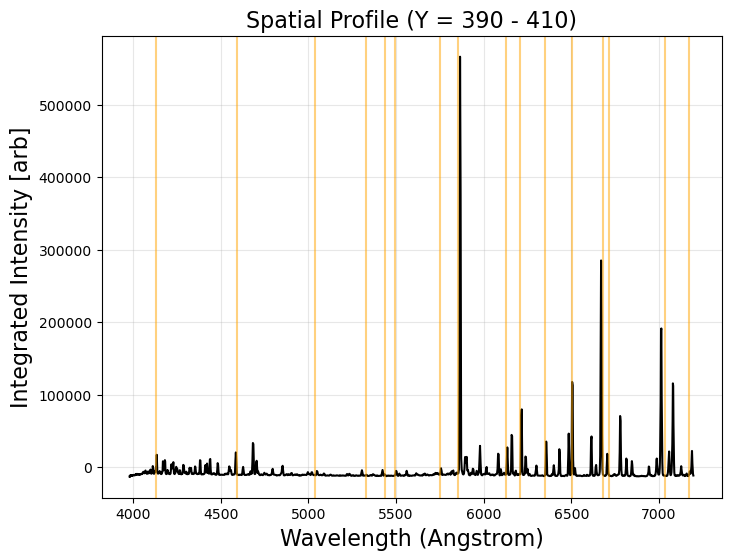

[7032. 6678. 5852. 4590. 6128. 6205. 6351. 6506. 6717. 5037. 5331. 5434.
 5494. 5748. 7174. 4131.]
[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  727.99445921  691.00370382  667.15561799  587.0314017     7.0725218
 1195.12487363]


In [52]:
plt.figure(figsize=(8,6))
plt.plot(nnnew_f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.show()

print(new_peaks)
print(new_centroids)


In [53]:
new_centroids = np.concatenate((new_centroids[:10], new_centroids[13:]))
new_peaks = np.concatenate((new_peaks[:10], new_peaks[13:]))

In [54]:
print(new_centroids)
print(new_peaks)

new_peaks[3] = 4545.0516
new_peaks[9] = 5017.1626

[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  587.0314017     7.0725218  1195.12487363]
[7032. 6678. 5852. 4590. 6128. 6205. 6351. 6506. 6717. 5037. 5748. 7174.
 4131.]


In [55]:
nnnew_p3, nnnew_c3 = np.polyfit(new_centroids, new_peaks, 3, cov=True)
nnnew_f3 = np.poly1d(nnnew_p3)

nnnew_errs = np.sqrt(np.diag(nnnew_c3), dtype=np.float128)

print(nnnew_p3)
print(nnnew_errs)

[ 2.09715989e-06 -3.88628272e-03 -9.09082337e-01  7.18750847e+03]
[5.47900155e-08 9.71985946e-05 4.72734060e-02 6.84129516e+00]


[ 124.29236986  278.82246524  552.75552329  975.11068652  467.06644151
  440.55807772  392.53799332  340.42316642  264.38510792  811.15955244
  587.0314017     7.0725218  1195.12487363]


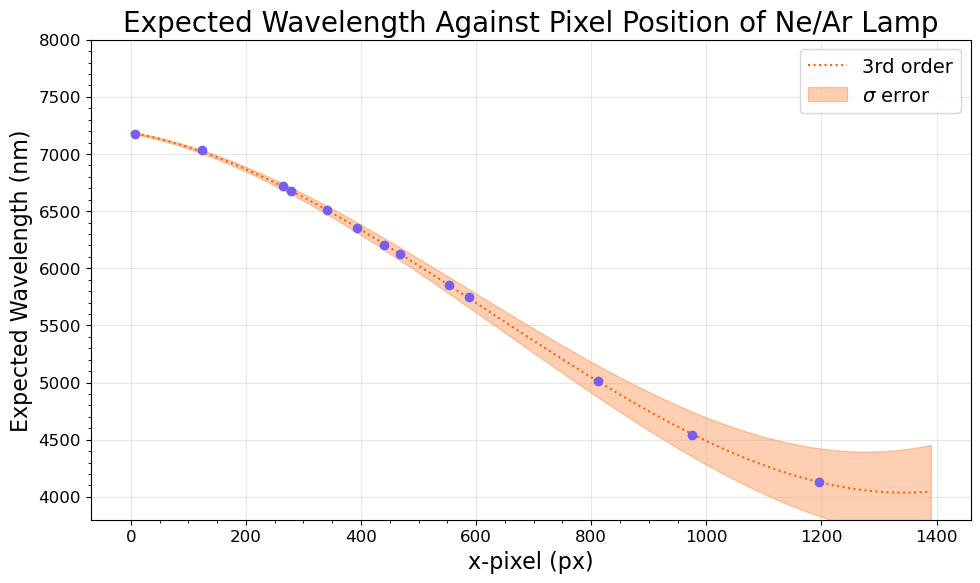

In [56]:
lin_range = np.arange(0, ncols, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
nnnew_f3_lo = np.poly1d(np.array([nnnew_p3[i] - nnnew_errs[i] for i in range(len(nnnew_p3))]))

nnnew_f3_hi = np.poly1d(np.array([nnnew_p3[i] + nnnew_errs[i] for i in range(len(nnnew_p3))]))

ax.scatter(new_centroids, new_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, nnnew_f3(lin_range), color="#FE6100", ls=":", label="3rd order")

ax.fill_between(lin_range, nnnew_f3_lo(lin_range), nnnew_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 100), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)
ax.set_ylim(3800, 8000)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

print(new_centroids)

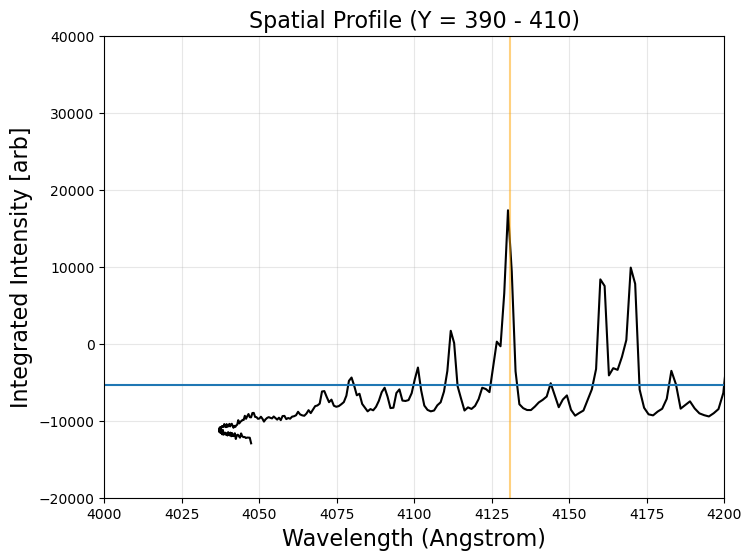

In [57]:
plt.figure(figsize=(8,6))
plt.plot(nnnew_f3(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xlim(4000, 4200)
plt.ylim(-20000, 40000)
plt.axhline(-5300)
plt.show()

The very first peak (very last peak index) corresponds to 4072.0043 A. We identify this with the previous peak very close to it and a similar structure at 4064.4036 A.

In [58]:
scp.signal.find_peaks(spectrum, -5300)

(array([   7,   55,   86,   99,  124,  138,  161,  206,  220,  235,  265,
         279,  290,  300,  335,  341,  348,  367,  378,  393,  412,  429,
         433,  440,  451,  459,  467,  479,  484,  505,  517,  523,  530,
         539,  541,  544,  553,  565,  587,  648,  667,  691,  728,  811,
         877,  897,  930,  938,  959,  975,  986,  990, 1017, 1035, 1043,
        1047, 1061, 1074, 1085, 1089, 1107, 1117, 1125, 1128, 1137, 1140,
        1143, 1156, 1165, 1169, 1172, 1184, 1195, 1198, 1211, 1221, 1244]),
 {'peak_heights': array([ 2.25980000e+04,  1.54766667e+03,  1.15772333e+05,  2.18770000e+04,
          1.91469667e+05,  1.21296667e+04,  1.10533333e+03,  8.54400000e+03,
          1.20860000e+04,  7.07636667e+04,  1.86433333e+04,  2.85236333e+05,
          3.23566667e+03,  4.25616667e+04, -1.17100000e+03,  1.17749333e+05,
          4.64836667e+04,  2.49763333e+04,  2.86466667e+03,  3.55000000e+04,
          2.40433333e+03, -2.11900000e+03,  1.48733333e+04,  7.99286667e+04,
  

In [59]:
new_centroids = np.concatenate((new_centroids, 
                               np.array([centroid(1244, 3, spectrum)])))
# we use around=3 here because of the second peak to the right
new_peaks = np.concatenate((new_peaks, np.array([4072.0043])))

In [60]:
nnnew_p3, nnnew_c3 = np.polyfit(new_centroids, new_peaks, 3, cov=True)
nnnew_f3 = np.poly1d(nnnew_p3)

nnnew_errs = np.sqrt(np.diag(nnnew_c3), dtype=np.float128)

print(nnnew_p3)
print(nnnew_errs)

[ 2.07999104e-06 -3.86114361e-03 -9.18020470e-01  7.18804888e+03]
[4.63856971e-08 8.62982232e-05 4.38260410e-02 6.58655964e+00]


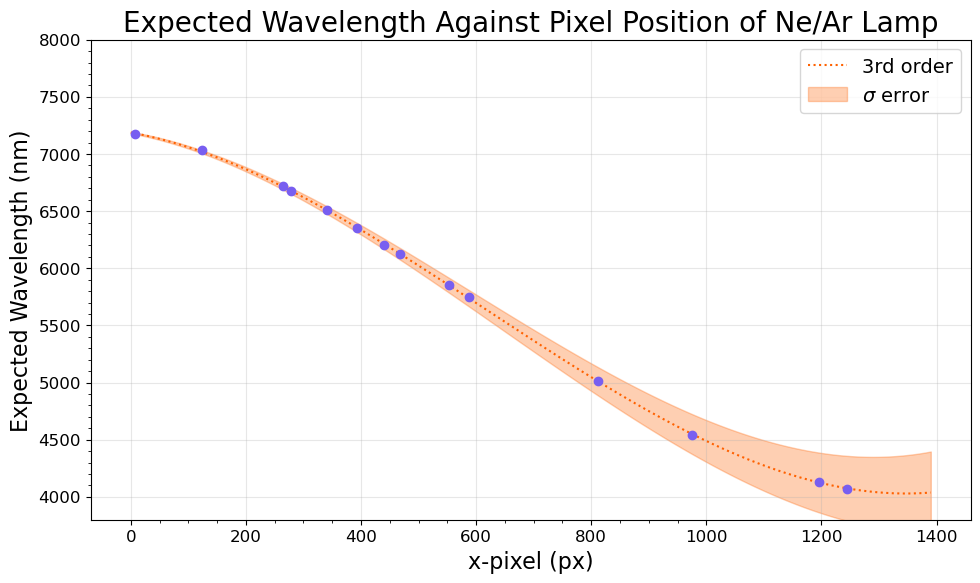

In [61]:
lin_range = np.arange(0, ncols, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
nnnew_f3_lo = np.poly1d(np.array([nnnew_p3[i] - nnnew_errs[i] for i in range(len(nnnew_p3))]))

nnnew_f3_hi = np.poly1d(np.array([nnnew_p3[i] + nnnew_errs[i] for i in range(len(nnnew_p3))]))

ax.scatter(new_centroids, new_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, nnnew_f3(lin_range), color="#FE6100", ls=":", label="3rd order")

ax.fill_between(lin_range, nnnew_f3_lo(lin_range), nnnew_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel Position of Ne/Ar Lamp", fontsize=20)

ax.set_ylabel("Expected Wavelength (nm)", fontsize=16)
ax.set_xlabel("x-pixel (px)", fontsize=16)

ax.set_yticks(np.arange(4000, 8000, 100), minor=True)
ax.set_xticks(np.arange(0, 1000, 50), minor=True)

ax.tick_params(labelsize=12)
ax.set_ylim(3800, 8000)

ax.legend(fontsize=14)
ax.grid(visible=True, alpha=0.3)

This is about as many peaks as we can use. The rest of the values represent few Angstroms, so we can omit the last few pixels where the fit begins to curve back up.

In [62]:
print(nnnew_f3(lin_range[1300:]))

print(f"\n{nnnew_f3(lin_range[1347])} at index 1347 is the lowest value \nbefore the curve rises again -> we will crop our data there")

[4039.02988405 4038.62269768 4038.22402543 4037.83387979 4037.45227323
 4037.07921823 4036.71472727 4036.35881284 4036.01148741 4035.67276346
 4035.34265348 4035.02116993 4034.70832531 4034.40413209 4034.10860276
 4033.82174978 4033.54358565 4033.27412284 4033.01337383 4032.76135111
 4032.51806714 4032.28353442 4032.05776542 4031.84077262 4031.6325685
 4031.43316555 4031.24257623 4031.06081304 4030.88788845 4030.72381494
 4030.56860499 4030.42227108 4030.2848257  4030.15628131 4030.03665041
 4029.92594546 4029.82417896 4029.73136338 4029.6475112  4029.5726349
 4029.50674697 4029.44985987 4029.40198609 4029.36313812 4029.33332842
 4029.31256949 4029.30087379 4029.29825382 4029.30472205 4029.32029095
 4029.34497302 4029.37878073 4029.42172656 4029.47382298 4029.53508249
 4029.60551756 4029.68514067 4029.7739643  4029.87200092 4029.97926303
 4030.0957631  4030.2215136  4030.35652703 4030.50081586 4030.65439256
 4030.81726963 4030.98945953 4031.17097476 4031.36182778 4031.56203108
 4031.77

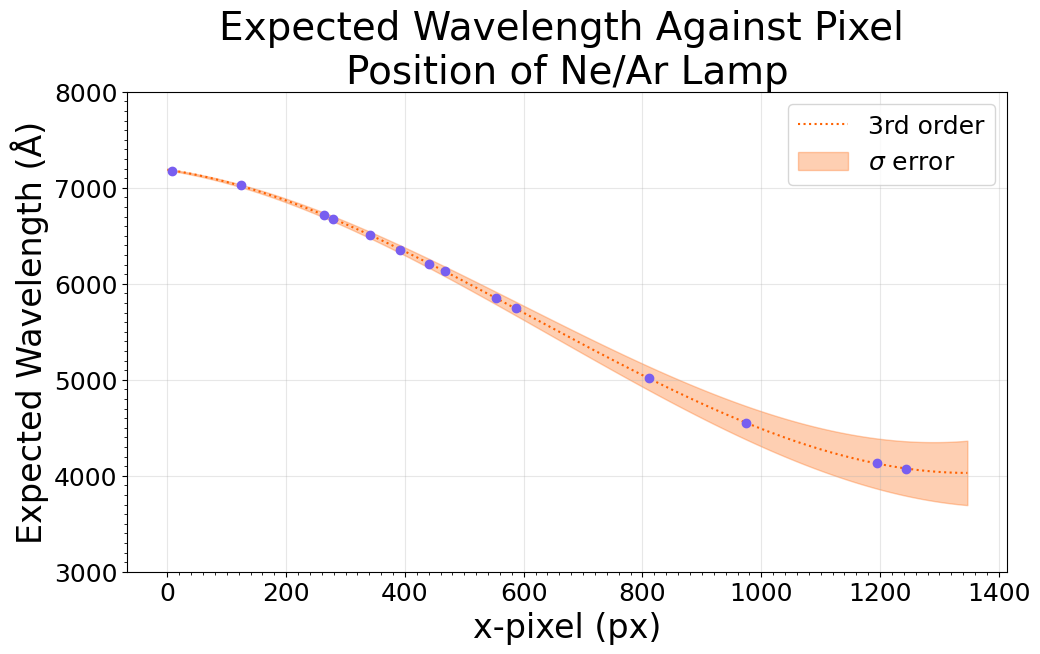

In [63]:
lin_range = np.arange(0, 1348, 1)
fig, ax = plt.subplots(1, 1)
plt.subplots_adjust(bottom=0, right=1.5, top=1, wspace=0.3, hspace=0.3)

##########
# DATA
##########
nnnew_f3_lo = np.poly1d(np.array([nnnew_p3[i] - nnnew_errs[i] for i in range(len(nnnew_p3))]))

nnnew_f3_hi = np.poly1d(np.array([nnnew_p3[i] + nnnew_errs[i] for i in range(len(nnnew_p3))]))

ax.scatter(new_centroids, new_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
ax.plot(lin_range, nnnew_f3(lin_range), color="#FE6100", ls=":", label="3rd order")

ax.fill_between(lin_range, nnnew_f3_lo(lin_range), nnnew_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

ax.set_title("Expected Wavelength Against Pixel \nPosition of Ne/Ar Lamp", fontsize=28)

ax.set_ylabel("Expected Wavelength (Å)", fontsize=24)
ax.set_xlabel("x-pixel (px)", fontsize=24)

ax.set_yticks(np.arange(3000, 8000, 100), minor=True)
ax.set_xticks(np.arange(0, 1400, 20), minor=True)

ax.tick_params(labelsize=18)
ax.set_ylim(3000, 8000)

ax.legend(fontsize=18)
ax.grid(visible=True, alpha=0.3)

Let's define a function that returns the calibration function so we can use it with our data:

In [64]:
def get_calibration():
    """
    Return the calibration polynomial of this notebook.
    """
    return nnnew_f3

Let's also find the residuals:

In [65]:
def third_residuals(x_arr, y_arr, a, b, c, d):
    """
    Return a NumPy array of the individual residuals of scatter points with coordinates from x_arr and y_arr 
    element pairs, using cubic regression of the form ax^3 + bx^2 + cx + d.
    """    
    residuals = []
    for i in range(len(x_arr)):
        residuals.append(y_arr[i] - f_cal(x_arr[i]))
    
    print(residuals)
    return np.array(residuals)

In [66]:
f_cal = nnnew_f3

f_cal_res = third_residuals(new_centroids, new_peaks, 
                            f_cal[0], f_cal[1], f_cal[2], f_cal[3])

print(f_cal_res)

rms_res = np.sqrt(np.sum(f_cal_res ** 2) / len(f_cal_res))

print(rms_res)

[np.float64(13.709421871469203), np.float64(1.0024378067955695), np.float64(-0.16522843844541057), np.float64(-5.0084799021433355), np.float64(-0.8921973241813248), np.float64(-7.0497001116782485), np.float64(-7.550002063238026), np.float64(-4.131087068674788), np.float64(3.11498486815708), np.float64(4.182793114722699), np.float64(8.660032131938351), np.float64(-7.363755644519188), np.float64(4.465737902248293), np.float64(-2.97495714245224)]
[13.70942187  1.00243781 -0.16522844 -5.0084799  -0.89219732 -7.04970011
 -7.55000206 -4.13108707  3.11498487  4.18279311  8.66003213 -7.36375564
  4.4657379  -2.97495714]
6.116961943913567


We can also plot these residuals:

Text(1400, 16.5, 'RMS of Residuals: 6.117')

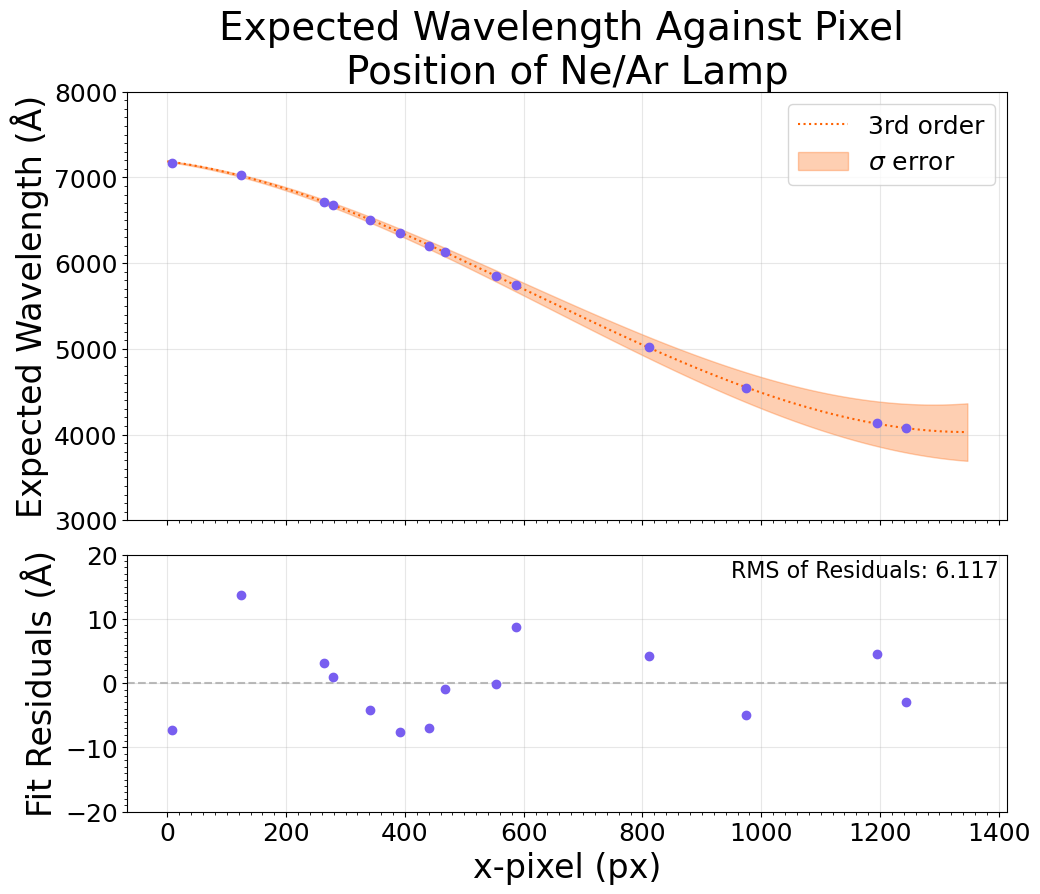

In [67]:
fig, axs = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [5, 3], 'bottom': 0, 
                                                        'right': 1.5, 'top': 1.5, 'wspace': 0.3, 'hspace': 0.1})

##########
# DATA
##########
axs[0].scatter(new_centroids, new_peaks, color="#785EF0", zorder=10)

#ax.plot(lin_range, f1(lin_range), color="#DC267F", ls="-", label="1st order", alpha=0.5)
axs[0].plot(lin_range, nnnew_f3(lin_range), color="#FE6100", ls=":", label="3rd order")

axs[0].fill_between(lin_range, nnnew_f3_lo(lin_range), nnnew_f3_hi(lin_range), color="#FE6100", alpha=0.3, label="$\\sigma$ error")

axs[0].set_title("Expected Wavelength Against Pixel \nPosition of Ne/Ar Lamp", fontsize=28)

axs[0].set_ylabel("Expected Wavelength (Å)", fontsize=24)
axs[1].set_xlabel("x-pixel (px)", fontsize=24)

axs[0].set_yticks(np.arange(3000, 8000, 100), minor=True)
axs[0].set_xticks(np.arange(0, 1400, 20), minor=True)

axs[0].tick_params(labelsize=18)
axs[0].set_ylim(3000, 8000)

axs[0].legend(fontsize=18)
axs[0].grid(visible=True, alpha=0.3)


axs[1].scatter(new_centroids, f_cal_res, color="#785EF0", zorder=10)
axs[1].set_ylim(-20, 20)
axs[1].set_yticks(np.arange(-20, 21, 1), minor=True)

axs[1].axhline(0, alpha=0.8, color="#AAAAAA", ls="dashed")

axs[1].set_ylabel("Fit Residuals (Å)", fontsize=24)
axs[1].grid(visible=True, alpha=0.3)
axs[1].tick_params(labelsize=18)

axs[1].text(1400, 16.5, f"RMS of Residuals: {np.round(rms_res, 3)}", horizontalalignment='right', fontsize=16)

In [68]:
print(f_cal)
print(nnnew_errs)

print((f_cal(0)))
print(f_cal(1348))

          3            2
2.08e-06 x - 0.003861 x - 0.918 x + 7188
[4.63856971e-08 8.62982232e-05 4.38260410e-02 6.58655964e+00]
7188.048876176742
4029.304722046811


We know want to find the resolving power of the spectrograph. We will do so by having a look at various peaks and their wavelength/peak FWHM, which gives an estimate of the resolving power in that wavelength area. We can use scipy's spline with spectrum/(peak/2) to find the FWHM at a peak:

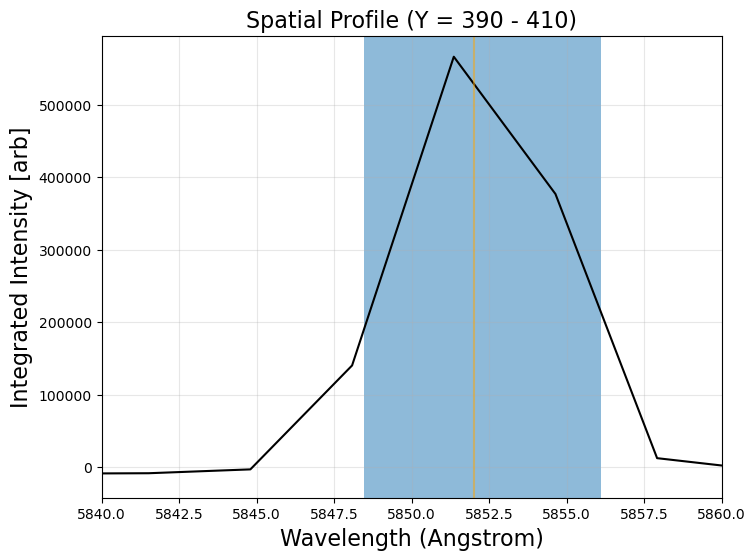

R at 5852.165: 765.9222651495795


In [105]:
from scipy.interpolate import UnivariateSpline

spline = UnivariateSpline(np.flip(f_cal(x_line)[540:560]), np.flip(spectrum[540:560] - spectrum[int(new_centroids[2])] / 2), s=0)
r1, r2 = spline.roots() # find the roots

plt.figure(figsize=(8,6))
plt.plot(f_cal(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xlim(5840, 5860)
plt.axvspan(r1, r2, alpha=0.5)

plt.show()

print(f"R at {np.round(f_cal(new_centroids[2]), 3)}: {f_cal(new_centroids[2]) / (np.abs(r2 - r1))}")

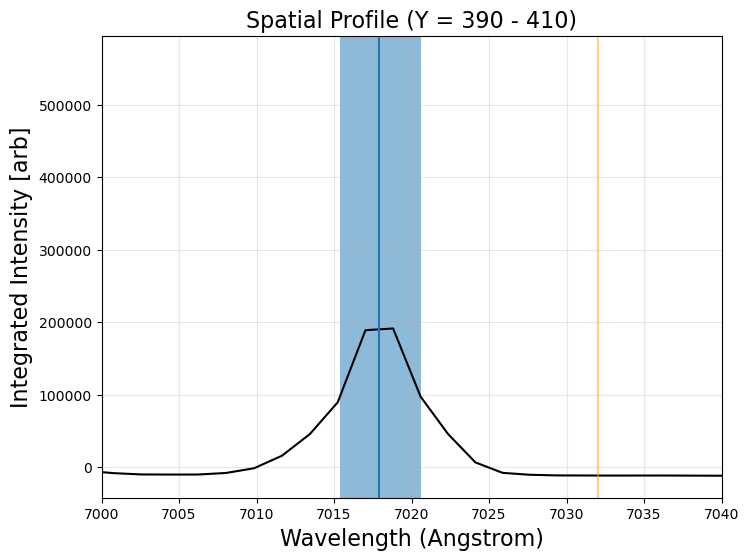

R at 7017.906 (remeasured centroid): 1334.155917283413


In [124]:
spline = UnivariateSpline(np.flip(f_cal(x_line)[120:140]), np.flip(spectrum[120:140] - spectrum[int(new_centroids[0])] / 2), s=0)
r1, r2 = spline.roots() # find the roots

plt.figure(figsize=(8,6))
plt.plot(f_cal(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xlim(7000, 7040)
plt.axvspan(r1, r2, alpha=0.5)
plt.axvline(f_cal(centroid(125, 5, spectrum)))
plt.show()

print(f"R at {np.round(f_cal(centroid(125, 5, spectrum)), 3)} (remeasured centroid): {f_cal(centroid(125, 5, spectrum)) / (np.abs(r2 - r1))}")

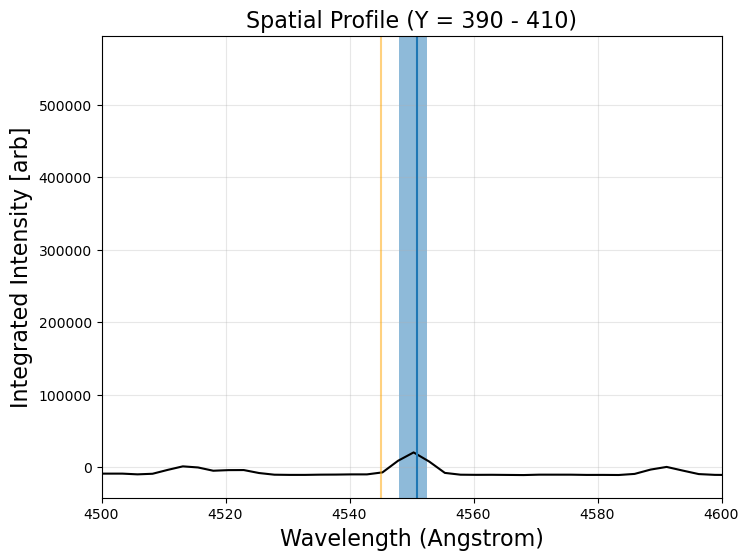

R at 4550.865 (remeasured centroid): 1001.6427849325636


In [139]:
spline = UnivariateSpline(np.flip(f_cal(x_line)[970:980]), np.flip(spectrum[970:980] - spectrum[int(new_centroids[3])] / 2), s=0)
r1, r2 = spline.roots() # find the roots

plt.figure(figsize=(8,6))
plt.plot(f_cal(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xlim(4500, 4600)
plt.axvspan(r1, r2, alpha=0.5)
plt.axvline(f_cal(centroid(975, 5, spectrum)))

plt.show()

print(f"R at {np.round(f_cal(centroid(975, 5, spectrum)), 3)} (remeasured centroid): {f_cal(centroid(975, 5, spectrum)) / (np.abs(r2 - r1))}")

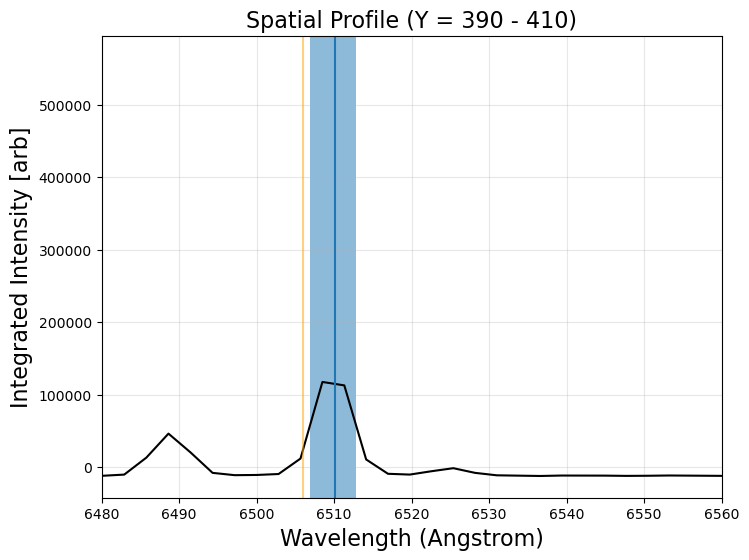

R at 6510.15 (remeasured centroid): 1092.129146524464


In [146]:
spline = UnivariateSpline(np.flip(f_cal(x_line)[335:345]), np.flip(spectrum[335:345] - spectrum[int(new_centroids[7])] / 2), s=0)
r1, r2 = spline.roots() # find the roots

plt.figure(figsize=(8,6))
plt.plot(f_cal(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xlim(6480, 6560)
plt.axvspan(r1, r2, alpha=0.5)
plt.axvline(f_cal(centroid(340, 5, spectrum)))

plt.show()

print(f"R at {np.round(f_cal(centroid(340, 5, spectrum)), 3)} (remeasured centroid): {f_cal(centroid(340, 5, spectrum)) / (np.abs(r2 - r1))}")

811.1595524379363


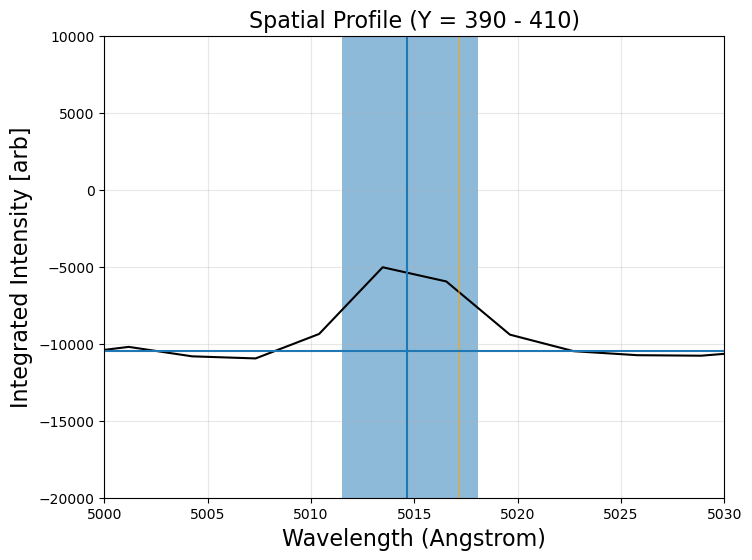

R at 5014.634 (remeasured centroid): 760.323046046499


In [182]:
spline = UnivariateSpline(np.flip(f_cal(x_line)[800:820]), np.flip(spectrum[800:820] - (spectrum[int(new_centroids[9])] + 10500) / 2) + 10500, s=0)
r1, r2 = spline.roots()

print(new_centroids[9])

plt.figure(figsize=(8,6))
plt.plot(f_cal(x_line), spectrum, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in new_peaks]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.xlim(5000, 5030)
plt.ylim(-20000, 10000)
plt.axvspan(r1, r2, alpha=0.5)
plt.axvline(f_cal(centroid(811, 10, spectrum)))
plt.axhline(-10500)
plt.show()

print(f"R at {np.round(f_cal(centroid(811, 10, spectrum)), 3)} (remeasured centroid): {f_cal(centroid(811, 10, spectrum)) / (np.abs(r2 - r1))}")